# **Project Title - Real Estate Investment Advisor: Predicting Property Profitability & Future Value**

### Project Type
Machine Learning + EDA + MLflow Experiment Tracking

### Contribution
Individual

##### **Name -** Punati Venkata Sai Ravish


### Dataset
`india_housing_prices.csv`

# **GitHub Link**
### https://github.com/pvsairavish/Real-Estate-Investment-Advisor-Predicting-Property-Profitability-Future-Value.git

# **Project Summary**

This project develops a machine-learning based **Real Estate Investment Advisor** using Indian housing data.

The solution contains two machine-learning tasks:

1. **Classification** - predict whether a property is a **Good Investment**.
2. **Regression** - predict the property's **estimated value after 5 years**.

The notebook follows an end-to-end ML workflow:

**Data Loading → Data Quality → EDA → Feature Engineering → Target Creation → Preprocessing → Model Training → Cross-Validation → Hyperparameter Tuning → Evaluation → MLflow Tracking → Best Model Saving**

The Streamlit deployment will be developed separately after this ML pipeline is completed and validated.

# **Problem Statement**

Potential real-estate investors need a data-driven way to compare properties and estimate their long-term value.

This project aims to build models that can:

- classify a property as a **Good Investment** or **Not a Good Investment**;
- estimate the property's **future price after five years**;
- identify the factors that influence investment potential and future property value;
- track model experiments using **MLflow**.

**Important modeling note:** the dataset does not contain an observed five-year future price. Therefore, the 5-year target must be engineered using a transparent appreciation assumption, as suggested in the project specification. The resulting regression is a scenario-based ML exercise, not a model trained on actual observed future sale prices.

# **Business Objectives**

- Help investors screen properties using consistent data-driven criteria.
- Estimate a property's potential five-year value.
- Identify important property and location characteristics.
- Compare multiple ML algorithms rather than relying on a single model.
- Track parameters, metrics and model artifacts with MLflow.
- Produce reusable preprocessing and model artifacts for the later Streamlit application.

# **General Guidelines**

1. Keep the notebook executable from top to bottom.
2. Use clear markdown before every major code cell.
3. Comment important logic inside code cells.
4. Use reproducible random seeds.
5. Avoid data leakage by fitting preprocessing only on training data.
6. Evaluate classification using Accuracy, Precision, Recall, F1-score and ROC-AUC where applicable.
7. Evaluate regression using MAE, RMSE and R².
8. Use cross-validation and hyperparameter tuning for the final candidate models.
9. Track experiments and artifacts with MLflow.
10. Save the final preprocessing objects and best models for deployment.

# **Import Libraries**

The notebook uses standard data-science libraries together with scikit-learn, XGBoost and MLflow.

The installation command is kept in a separate cell so the notebook can be reproduced easily on Kaggle.

In [1]:
import time
# Install packages required for the ML workflow on Kaggle.
# If a package is already installed, pip will normally reuse/upgrade it.
!pip install -q mlflow xgboost joblib h5py

# **Import Required Packages**

Import all libraries in one place so the notebook has a clear dependency section.

In [2]:
import os
import glob
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    KFold,
    cross_validate,
    RandomizedSearchCV
)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier, XGBRegressor

import mlflow
import mlflow.sklearn

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("Libraries imported successfully.")

Libraries imported successfully.


# **Kaggle Configuration**

The dataset path can vary depending on the Kaggle dataset name. Instead of hard-coding a folder name, the code searches `/kaggle/input` for `india_housing_prices.csv`.

A local fallback is included so the same notebook structure can also be tested outside Kaggle.

In [3]:
DATA_FILENAME = "india_housing_prices.csv"

kaggle_matches = glob.glob(f"/kaggle/input/**/{DATA_FILENAME}", recursive=True)

if kaggle_matches:
    DATA_PATH = kaggle_matches[0]
elif os.path.exists(f"/kaggle/working/{DATA_FILENAME}"):
    DATA_PATH = f"/kaggle/working/{DATA_FILENAME}"
elif os.path.exists(f"/mnt/data/{DATA_FILENAME}"):
    DATA_PATH = f"/mnt/data/{DATA_FILENAME}"
else:
    raise FileNotFoundError(
        f"Could not find {DATA_FILENAME}. "
        "Upload the CSV to Kaggle or place it in /kaggle/working."
    )

OUTPUT_DIR = Path("/kaggle/working/real_estate_ml")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset path:", DATA_PATH)
print("Output directory:", OUTPUT_DIR)

Dataset path: /kaggle/input/datasets/sairavishpv/real-estate-investment-advisor-dataset/india_housing_prices.csv
Output directory: /kaggle/working/real_estate_ml


# **Load Dataset**

Load the complete housing dataset and make a working copy.

The provided dataset contains **250,000 property records and 23 columns**. We keep the full dataset because it is large enough for meaningful model training.

In [4]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Rows:", f"{df.shape[0]:,}")
print("Columns:", df.shape[1])
df.head()

Dataset loaded successfully.
Rows: 250,000
Columns: 23


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.7600,0.1000,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.5200,0.0800,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.7900,0.0500,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.2900,0.1100,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.9000,0.0400,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


# **Dataset First Look**

Inspect the first and last records to verify that the file was loaded correctly and that the columns have the expected structure.

In [5]:
display(df.head())
display(df.tail())

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.7600,0.1000,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.5200,0.0800,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.7900,0.0500,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.2900,0.1100,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.9000,0.0400,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
249995,249996,Gujarat,Ahmedabad,Locality_187,Independent House,5,1995,274.7500,0.1400,1995,Furnished,19,7,30,8,6,Low,No,No,"Playground, Garden, Gym, Clubhouse, Pool",East,Broker,Under_Construction
249996,249997,Tamil Nadu,Chennai,Locality_348,Apartment,1,2293,13.4000,0.0100,2013,Semi-furnished,15,25,12,8,10,Low,No,No,Playground,South,Broker,Ready_to_Move
249997,249998,Telangana,Warangal,Locality_225,Villa,4,2910,236.9400,0.0800,2003,Furnished,21,30,22,10,4,High,Yes,Yes,Playground,South,Builder,Under_Construction
249998,249999,Odisha,Cuttack,Locality_138,Villa,1,1149,141.6600,0.1200,2007,Unfurnished,14,11,18,3,7,Low,Yes,Yes,"Playground, Gym, Pool",South,Owner,Ready_to_Move
249999,250000,Haryana,Gurgaon,Locality_268,Independent House,3,4313,199.6900,0.0500,1990,Semi-furnished,22,28,35,10,6,Medium,No,No,"Gym, Garden",South,Owner,Under_Construction


# **Dataset Rows & Columns Count**

Confirm the exact dataset dimensions before preprocessing.

In [6]:
print(f"Number of rows    : {df.shape[0]:,}")
print(f"Number of columns : {df.shape[1]}")

Number of rows    : 250,000
Number of columns : 23


# **Dataset Information**

Check data types and non-null counts.

This step is important before choosing preprocessing methods for numerical and categorical features.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  object 
 2   City                            250000 non-null  object 
 3   Locality                        250000 non-null  object 
 4   Property_Type                   250000 non-null  object 
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  object 
 11  Floor_No                        250000 non-null  int64  
 12  Total_Floors    

# **Duplicate Value Count**

Check for completely duplicated rows.

Duplicate records can distort both exploratory analysis and model evaluation.

In [8]:
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


# **Missing / Null Value Count**

Check every column for missing values.

The supplied dataset is expected to be complete, but the check is retained so the notebook remains robust if the Kaggle copy changes.

In [9]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_table = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": missing_pct
})

display(missing_table[missing_table["Missing_Count"] > 0])

if missing.sum() == 0:
    print("No missing values found.")

,Missing_Count,Missing_Percentage


No missing values found.


# **Dataset Columns**

List all variables so the feature-selection stage is explicit and reproducible.

In [10]:
for i, column in enumerate(df.columns, start=1):
    print(f"{i:02d}. {column}")

01. ID
02. State
03. City
04. Locality
05. Property_Type
06. BHK
07. Size_in_SqFt
08. Price_in_Lakhs
09. Price_per_SqFt
10. Year_Built
11. Furnished_Status
12. Floor_No
13. Total_Floors
14. Age_of_Property
15. Nearby_Schools
16. Nearby_Hospitals
17. Public_Transport_Accessibility
18. Parking_Space
19. Security
20. Amenities
21. Facing
22. Owner_Type
23. Availability_Status


# **Statistical Description**

Review numerical distributions, ranges and potential anomalies before feature engineering.

In [11]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
ID,"250,000.0000","125,000.5000","72,168.9280",1.0000,"62,500.7500","125,000.5000","187,500.2500","250,000.0000"
BHK,"250,000.0000",2.9994,1.4155,1.0000,2.0000,3.0000,4.0000,5.0000
Size_in_SqFt,"250,000.0000","2,749.8132","1,300.6070",500.0000,"1,623.0000","2,747.0000","3,874.0000","5,000.0000"
Price_in_Lakhs,"250,000.0000",254.5869,141.3499,10.0000,132.5500,253.8700,376.8800,500.0000
Price_per_SqFt,"250,000.0000",0.1306,0.1307,0.0000,0.0500,0.0900,0.1600,0.9900
Year_Built,"250,000.0000","2,006.5200",9.8086,"1,990.0000","1,998.0000","2,007.0000","2,015.0000","2,023.0000"
Floor_No,"250,000.0000",14.9668,8.9480,0.0000,7.0000,15.0000,23.0000,30.0000
Total_Floors,"250,000.0000",15.5030,8.6716,1.0000,8.0000,15.0000,23.0000,30.0000
Age_of_Property,"250,000.0000",18.4800,9.8086,2.0000,10.0000,18.0000,27.0000,35.0000
Nearby_Schools,"250,000.0000",5.4999,2.8786,1.0000,3.0000,5.0000,8.0000,10.0000


# **Unique Values of Important Variables**

Check the cardinality of categorical variables.

`Locality` and `Amenities` have more categories than most other variables, so their encoding needs to be handled efficiently.

In [12]:
categorical_cols = df.select_dtypes(include="object").columns

unique_summary = pd.DataFrame({
    "Column": categorical_cols,
    "Unique_Values": [df[c].nunique() for c in categorical_cols]
}).sort_values("Unique_Values", ascending=False)

display(unique_summary)

print("\nSelected numerical cardinalities:")
for col in ["BHK", "Floor_No", "Total_Floors", "Nearby_Schools", "Nearby_Hospitals"]:
    print(f"{col}: {df[col].nunique()}")

,Column,Unique_Values
2,Locality,500
8,Amenities,325
1,City,42
0,State,20
9,Facing,4
3,Property_Type,3
4,Furnished_Status,3
5,Public_Transport_Accessibility,3
10,Owner_Type,3
6,Parking_Space,2



Selected numerical cardinalities:
BHK: 5
Floor_No: 31
Total_Floors: 30
Nearby_Schools: 10
Nearby_Hospitals: 10


# **Data Quality Checks**

Perform domain-oriented validation before modeling.

The original dataset contains `Price_per_SqFt = 0` for some records. Since price and area are both positive, zero price per square foot is not economically valid and should be treated as a missing/derived value rather than as a real observation.

In [13]:
quality_checks = {
    "Negative Price": int((df["Price_in_Lakhs"] < 0).sum()),
    "Non-positive Size": int((df["Size_in_SqFt"] <= 0).sum()),
    "Non-positive Price_per_SqFt": int((df["Price_per_SqFt"] <= 0).sum()),
    "Invalid Year_Built": int(((df["Year_Built"] < 1900) | (df["Year_Built"] > 2026)).sum()),
    "Invalid Floor_No": int((df["Floor_No"] < 0).sum()),
    "Invalid Total_Floors": int((df["Total_Floors"] <= 0).sum()),
}

display(pd.Series(quality_checks, name="Count").to_frame())

print("Price_per_SqFt zero values will be recalculated from price and size.")

,Count
Negative Price,0
Non-positive Size,0
Non-positive Price_per_SqFt,2534
Invalid Year_Built,0
Invalid Floor_No,0
Invalid Total_Floors,0


Price_per_SqFt zero values will be recalculated from price and size.


# **Data Cleaning and Working Copy**

Create a clean modeling dataframe.

`Price_per_SqFt` is recalculated from the source price and size so the derived metric is internally consistent. This also removes the zero-value issue without deleting otherwise useful property records.

In [14]:
data = df.copy()

# Remove exact duplicate records if any exist.
data = data.drop_duplicates().reset_index(drop=True)

# Recalculate the derived price-per-square-foot measure.
data["Price_per_SqFt"] = (
    data["Price_in_Lakhs"] / data["Size_in_SqFt"]
).replace([np.inf, -np.inf], np.nan)

# Ensure numeric columns have numeric dtypes.
numeric_expected = [
    "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt",
    "Year_Built", "Floor_No", "Total_Floors", "Age_of_Property",
    "Nearby_Schools", "Nearby_Hospitals"
]

for col in numeric_expected:
    data[col] = pd.to_numeric(data[col], errors="coerce")

print("Cleaned shape:", data.shape)
print("Remaining missing values:", int(data.isna().sum().sum()))

Cleaned shape: (250000, 23)
Remaining missing values: 0


# **Feature Engineering**

Create features that represent useful real-estate concepts:

- `Floor_Ratio` measures the property's floor position relative to the building.
- `Amenities_Count` counts listed amenities.
- `Has_Parking`, `Has_Security` and `Is_Ready_To_Move` convert binary text attributes into numeric indicators.
- `Property_Age_Band` gives a simple age category.
- `School_Hospital_Access` combines nearby education and healthcare availability.

The original `ID` is not used as a predictive feature because it is only an identifier.

In [15]:
def count_amenities(value):
    if pd.isna(value) or str(value).strip() == "":
        return 0
    return len([x for x in str(value).split(",") if x.strip()])

data["Amenities_Count"] = data["Amenities"].apply(count_amenities)

data["Has_Parking"] = data["Parking_Space"].map({"Yes": 1, "No": 0}).fillna(0).astype(int)
data["Has_Security"] = data["Security"].map({"Yes": 1, "No": 0}).fillna(0).astype(int)
data["Is_Ready_To_Move"] = data["Availability_Status"].map(
    {"Ready_to_Move": 1, "Under_Construction": 0}
).fillna(0).astype(int)

data["Floor_Ratio"] = (
    data["Floor_No"] / data["Total_Floors"].replace(0, np.nan)
).clip(lower=0, upper=1)

data["School_Hospital_Access"] = data["Nearby_Schools"] + data["Nearby_Hospitals"]

data["Property_Age_Band"] = pd.cut(
    data["Age_of_Property"],
    bins=[-1, 5, 15, 25, 100],
    labels=["New", "Moderate", "Old", "Very_Old"]
)

display(data.head())

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status,Amenities_Count,Has_Parking,Has_Security,Is_Ready_To_Move,Floor_Ratio,School_Hospital_Access,Property_Age_Band
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.7600,0.1033,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move,5,0,0,1,1.0000,13,Very_Old
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.5200,0.0827,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction,5,0,1,0,1.0000,9,Old
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.7900,0.0505,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move,4,1,0,1,0.7037,17,Very_Old
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.2900,0.1096,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move,5,1,1,1,0.8077,12,Very_Old
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.9000,0.0379,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move,5,0,1,1,1.0000,13,Old


# **EDA Chart 1 - Property Price Distribution**

A histogram shows the distribution and concentration of current property prices.

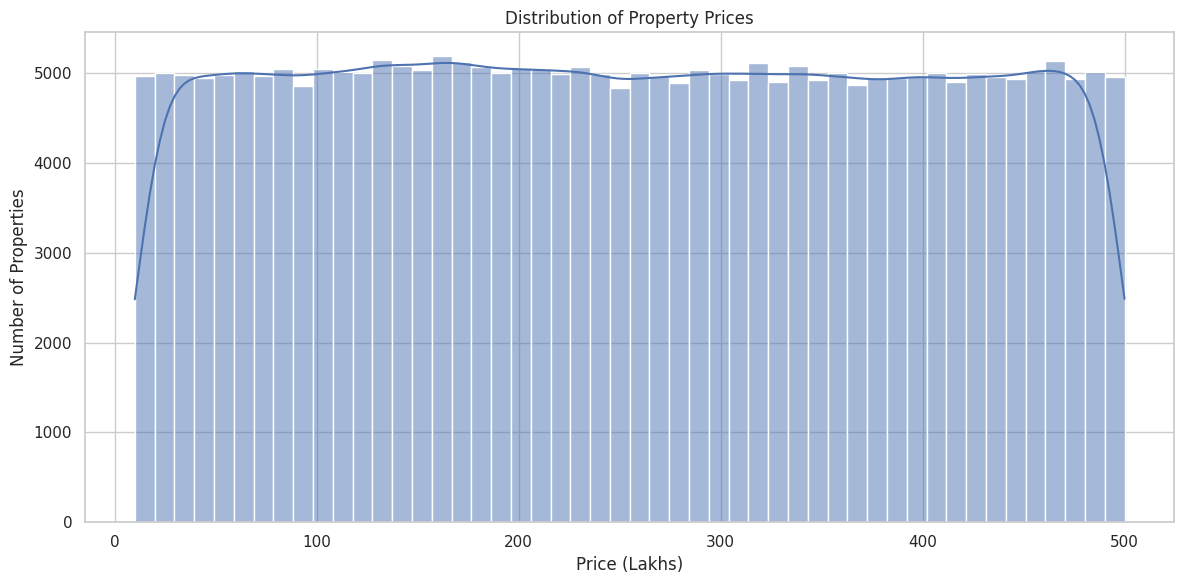

In [16]:
plt.figure(figsize=(12, 6))
sns.histplot(data=data, x="Price_in_Lakhs", bins=50, kde=True)
plt.title("Distribution of Property Prices")
plt.xlabel("Price (Lakhs)")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.show()

### **Chart 1 Interpretation**

**Why this chart?**  
A histogram is appropriate for understanding the distribution of a continuous numerical variable.

**Insight:**  
It shows where property prices are concentrated and whether the dataset contains strong skewness or extreme values.

**Business impact:**  
Understanding the price distribution helps investors identify the dominant market segment and supports sensible pricing thresholds.

**Potential negative insight:**  
Extreme price observations may influence models disproportionately and should be checked during model diagnostics.

# **EDA Chart 2 - Property Size Distribution**

Analyze the distribution of property area in square feet.

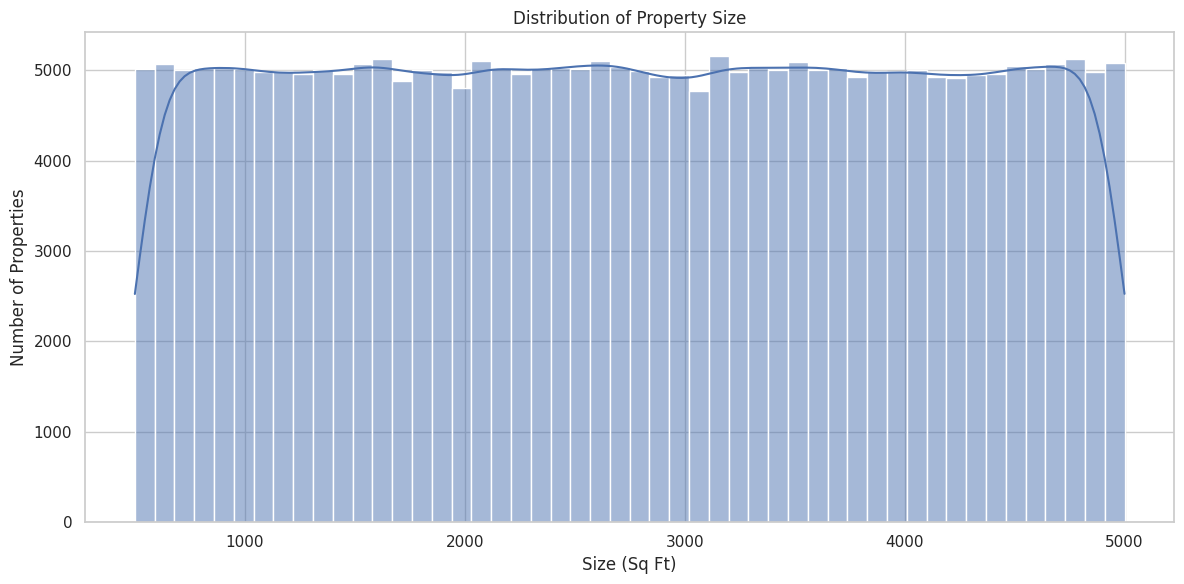

In [17]:
plt.figure(figsize=(12, 6))
sns.histplot(data=data, x="Size_in_SqFt", bins=50, kde=True)
plt.title("Distribution of Property Size")
plt.xlabel("Size (Sq Ft)")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.show()

### **Chart 2 Interpretation**

**Why this chart?**  
A histogram clearly shows the spread and concentration of property sizes.

**Insight:**  
It helps determine the typical property-size segment represented in the dataset.

**Business impact:**  
Investors can understand which property sizes dominate the market and compare individual properties with the overall market.

# **EDA Chart 3 - Property Size vs Current Price**

A scatter plot is used to examine whether larger properties generally have higher prices.

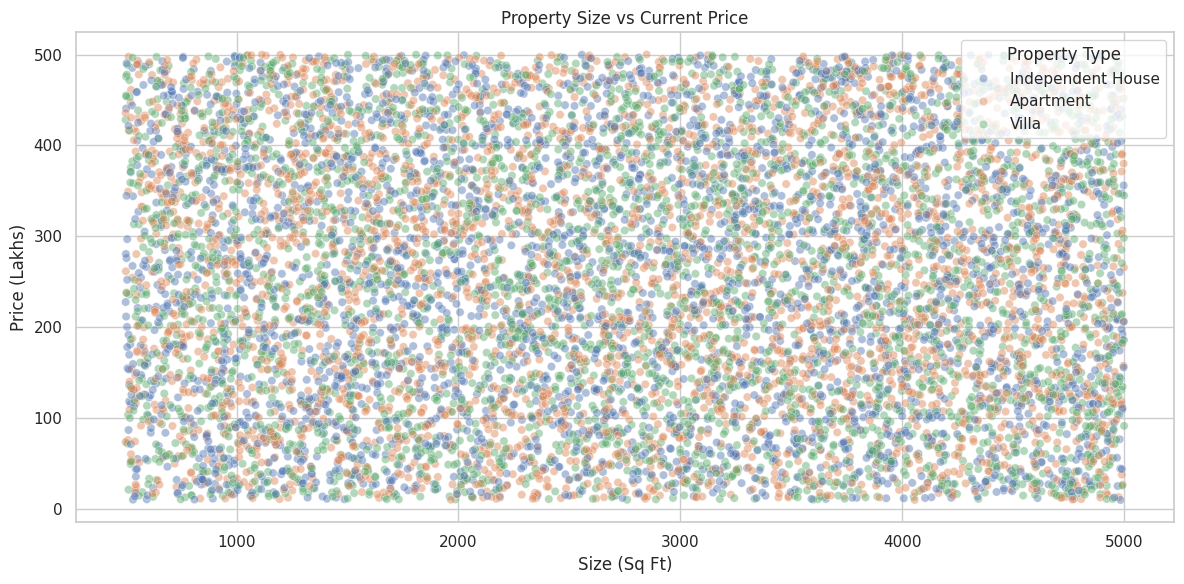

In [18]:
sample_plot = data.sample(min(10000, len(data)), random_state=RANDOM_STATE)

plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=sample_plot,
    x="Size_in_SqFt",
    y="Price_in_Lakhs",
    hue="Property_Type",
    alpha=0.45
)
plt.title("Property Size vs Current Price")
plt.xlabel("Size (Sq Ft)")
plt.ylabel("Price (Lakhs)")
plt.legend(title="Property Type")
plt.tight_layout()
plt.show()

### **Chart 3 Interpretation**

**Why this chart?**  
A scatter plot is suitable for examining the relationship between two numerical variables.

**Insight:**  
The plot shows whether price generally increases with property size and whether property type changes that relationship.

**Business impact:**  
The relationship is important when evaluating whether a property's price is reasonable relative to its size.

# **EDA Chart 4 - Average Price by Property Type**

Compare the average property price for apartments, villas and independent houses.

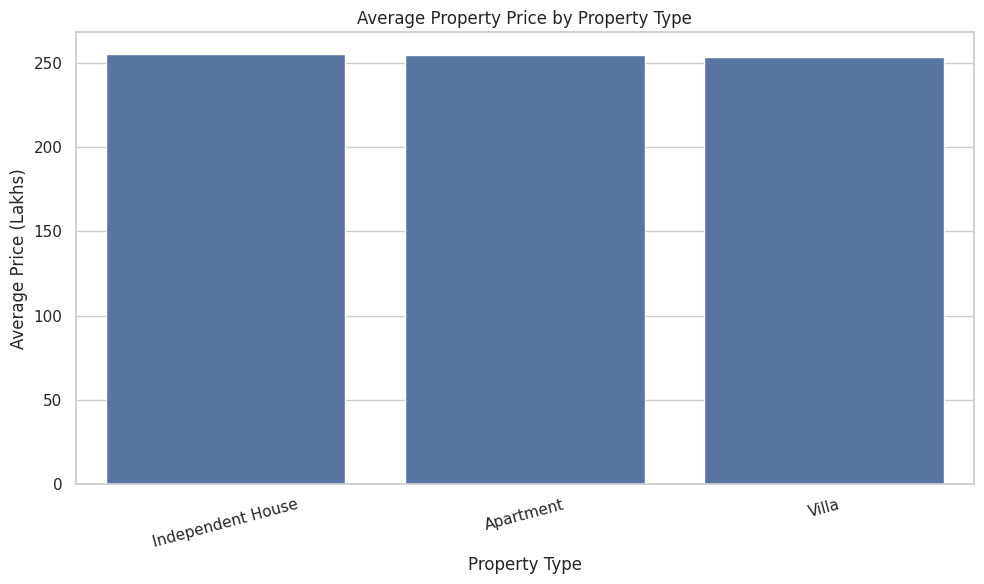

In [19]:
avg_price_type = (
    data.groupby("Property_Type", as_index=False)["Price_in_Lakhs"]
    .mean()
    .sort_values("Price_in_Lakhs", ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(data=avg_price_type, x="Property_Type", y="Price_in_Lakhs")
plt.title("Average Property Price by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Average Price (Lakhs)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### **Chart 4 Interpretation**

**Why this chart?**  
A bar chart is effective for comparing independent categorical groups.

**Insight:**  
It shows which property types command higher average prices.

**Business impact:**  
Investors can compare property categories before considering expected returns and affordability.

# **EDA Chart 5 - Average Price per Sq Ft by Property Type**

Compare normalized property prices rather than only total property prices.

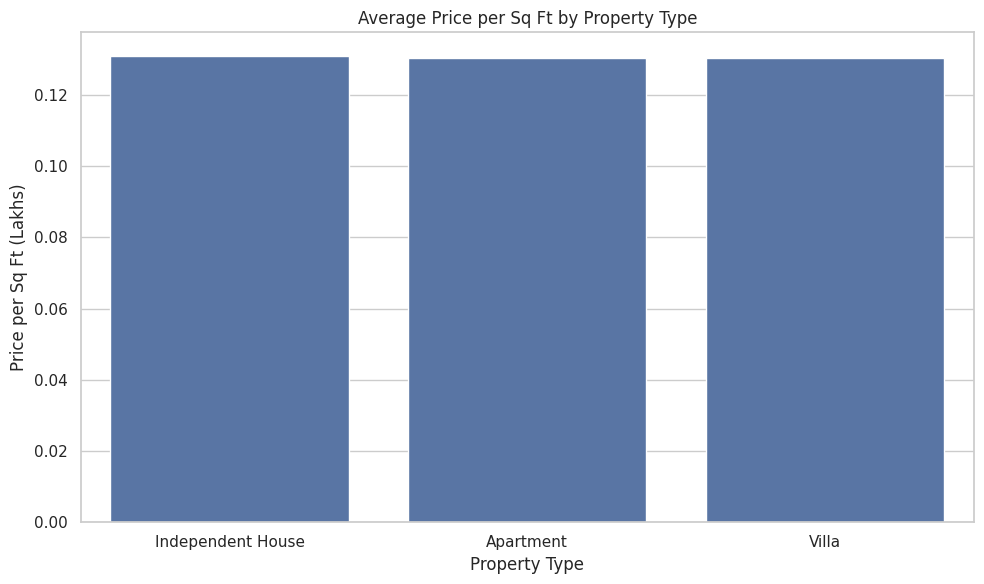

In [20]:
avg_ppsft_type = (
    data.groupby("Property_Type", as_index=False)["Price_per_SqFt"]
    .mean()
    .sort_values("Price_per_SqFt", ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(data=avg_ppsft_type, x="Property_Type", y="Price_per_SqFt")
plt.title("Average Price per Sq Ft by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Price per Sq Ft (Lakhs)")
plt.tight_layout()
plt.show()

### **Chart 5 Interpretation**

**Why this chart?**  
Price per square foot normalizes properties of different sizes and makes category comparison fairer.

**Insight:**  
Differences indicate that property type can influence the amount paid for each unit of area.

**Business impact:**  
This metric is useful when screening properties for relative value.

# **EDA Chart 6 - Average Price by Top Cities**

Rank cities by their average property price.

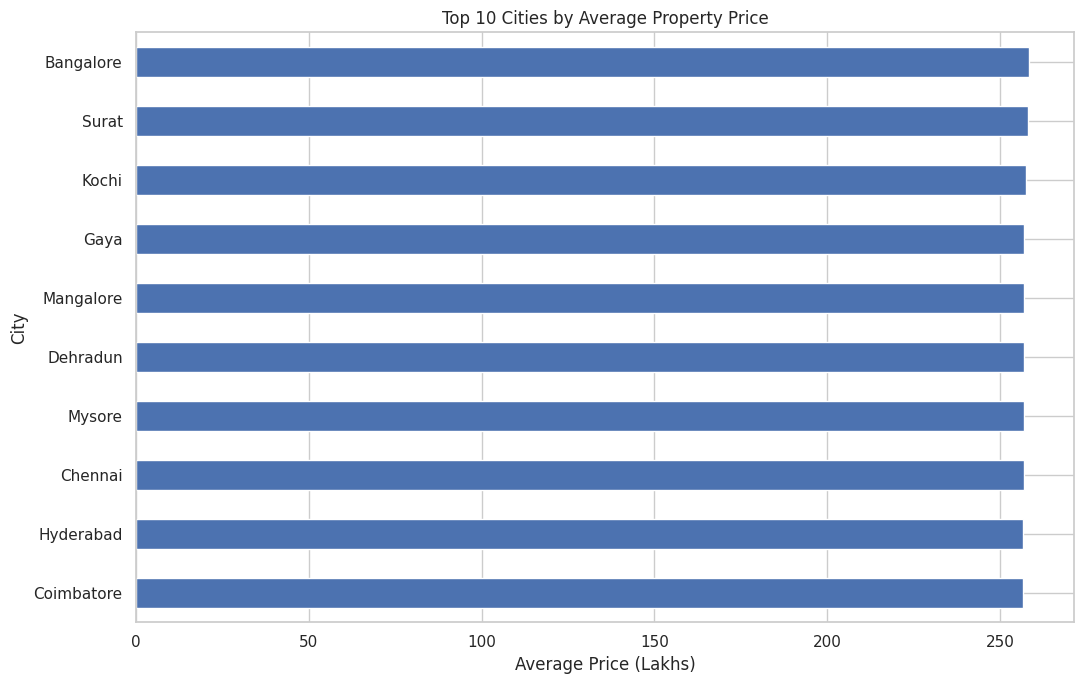

In [21]:
top_cities = (
    data.groupby("City")["Price_in_Lakhs"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(11, 7))
top_cities.plot(kind="barh")
plt.title("Top 10 Cities by Average Property Price")
plt.xlabel("Average Price (Lakhs)")
plt.ylabel("City")
plt.tight_layout()
plt.show()

### **Chart 6 Interpretation**

**Why this chart?**  
A horizontal bar chart makes city names easy to read while ranking categories.

**Insight:**  
It highlights the cities with the highest average property prices.

**Business impact:**  
City-level price differences are important for investment budget planning and location selection.

# **EDA Chart 7 - BHK Distribution**

Examine the distribution of bedroom counts in the housing market.

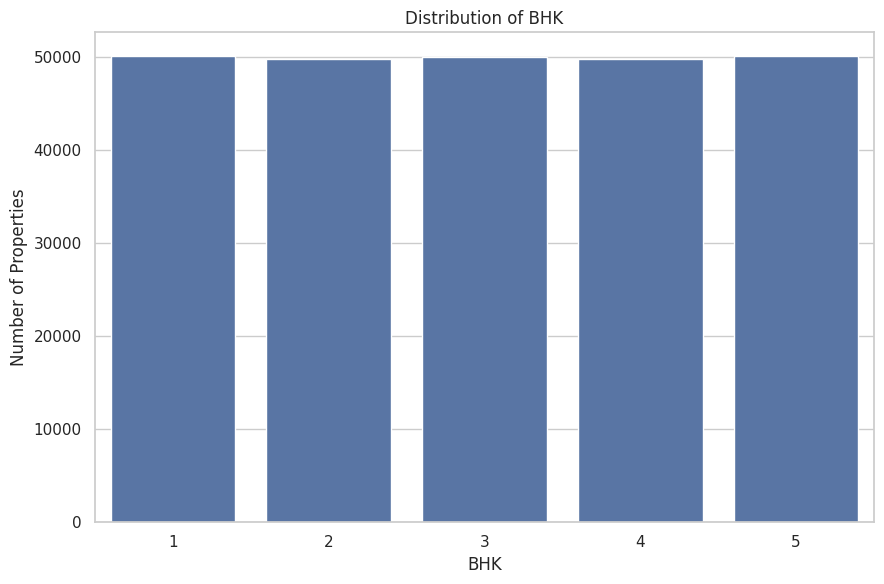

In [22]:
bhk_counts = data["BHK"].value_counts().sort_index()

plt.figure(figsize=(9, 6))
sns.barplot(x=bhk_counts.index.astype(str), y=bhk_counts.values)
plt.title("Distribution of BHK")
plt.xlabel("BHK")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.show()

### **Chart 7 Interpretation**

**Why this chart?**  
A bar chart is appropriate for comparing discrete BHK categories.

**Insight:**  
It shows which bedroom configurations dominate the dataset.

**Business impact:**  
BHK demand can guide investors toward property configurations with broader market appeal.

# **EDA Chart 8 - Furnishing Status vs Price**

Compare property prices across furnishing categories.

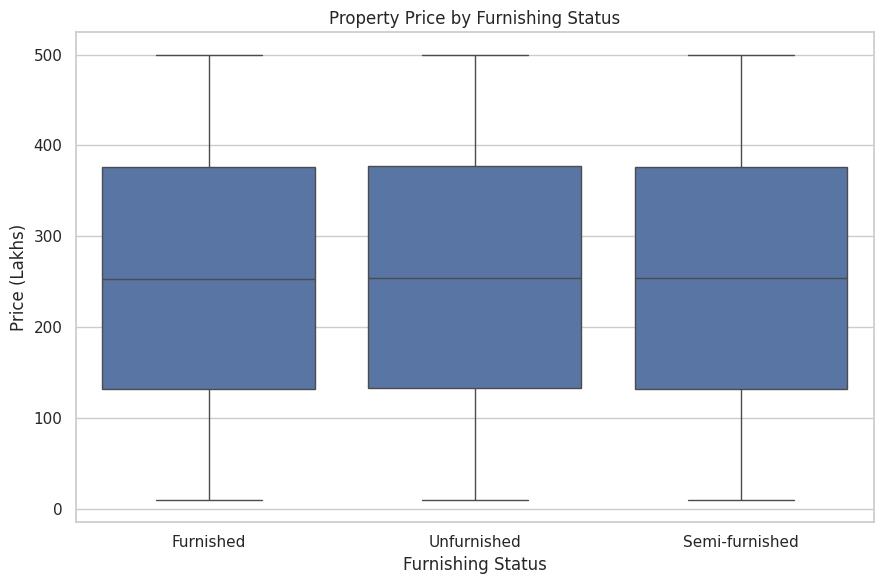

In [23]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=data, x="Furnished_Status", y="Price_in_Lakhs")
plt.title("Property Price by Furnishing Status")
plt.xlabel("Furnishing Status")
plt.ylabel("Price (Lakhs)")
plt.tight_layout()
plt.show()

### **Chart 8 Interpretation**

**Why this chart?**  
A boxplot compares distributions rather than only averages and can reveal outliers.

**Insight:**  
The chart shows whether furnishing status is associated with different price distributions.

**Business impact:**  
Investors can evaluate whether furnishing provides a meaningful price premium.

# **EDA Chart 9 - Public Transport Accessibility vs Price**

Analyze whether accessibility levels are associated with property prices.

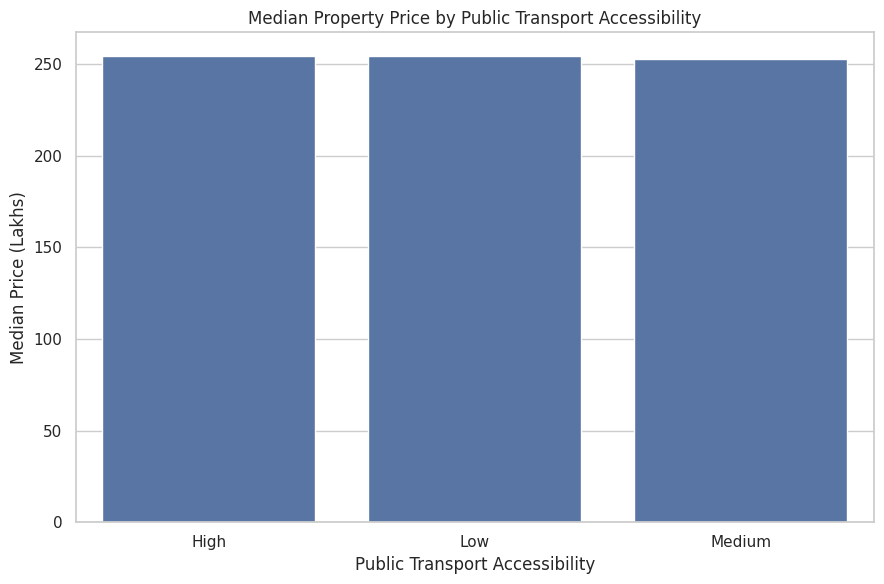

In [24]:
transport_price = (
    data.groupby("Public_Transport_Accessibility", as_index=False)["Price_in_Lakhs"]
    .median()
)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=transport_price,
    x="Public_Transport_Accessibility",
    y="Price_in_Lakhs"
)
plt.title("Median Property Price by Public Transport Accessibility")
plt.xlabel("Public Transport Accessibility")
plt.ylabel("Median Price (Lakhs)")
plt.tight_layout()
plt.show()

### **Chart 9 Interpretation**

**Why this chart?**  
A bar chart gives a direct comparison of median prices across accessibility groups.

**Insight:**  
It helps reveal whether transport accessibility is associated with higher or lower property prices.

**Business impact:**  
Transport access can be a useful location-quality signal when evaluating properties.

# **EDA Chart 10 - Amenities Count vs Price**

Use the engineered `Amenities_Count` feature to examine whether more amenities are associated with higher property prices.

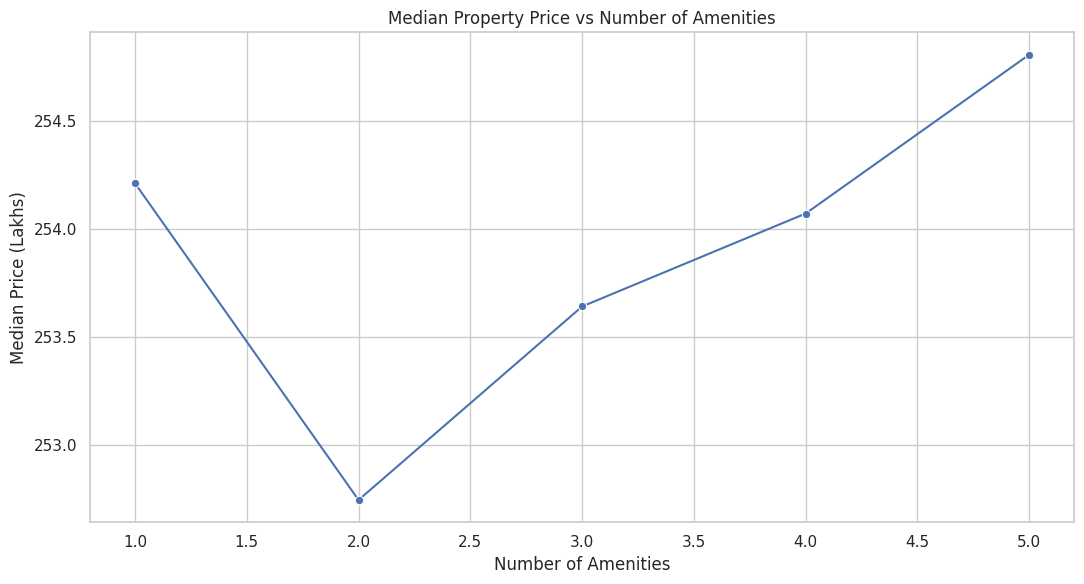

In [25]:
amenity_price = (
    data.groupby("Amenities_Count", as_index=False)["Price_in_Lakhs"]
    .median()
)

plt.figure(figsize=(11, 6))
sns.lineplot(
    data=amenity_price,
    x="Amenities_Count",
    y="Price_in_Lakhs",
    marker="o"
)
plt.title("Median Property Price vs Number of Amenities")
plt.xlabel("Number of Amenities")
plt.ylabel("Median Price (Lakhs)")
plt.tight_layout()
plt.show()

### **Chart 10 Interpretation**

**Why this chart?**  
A line chart is useful for observing an ordered relationship between amenity count and median price.

**Insight:**  
The pattern shows whether properties with more listed amenities tend to have different price levels.

**Business impact:**  
Amenities can contribute to buyer attractiveness and potentially influence investment demand.

# **EDA Chart 11 - Age of Property vs Price**

Analyze whether property age is related to current price.

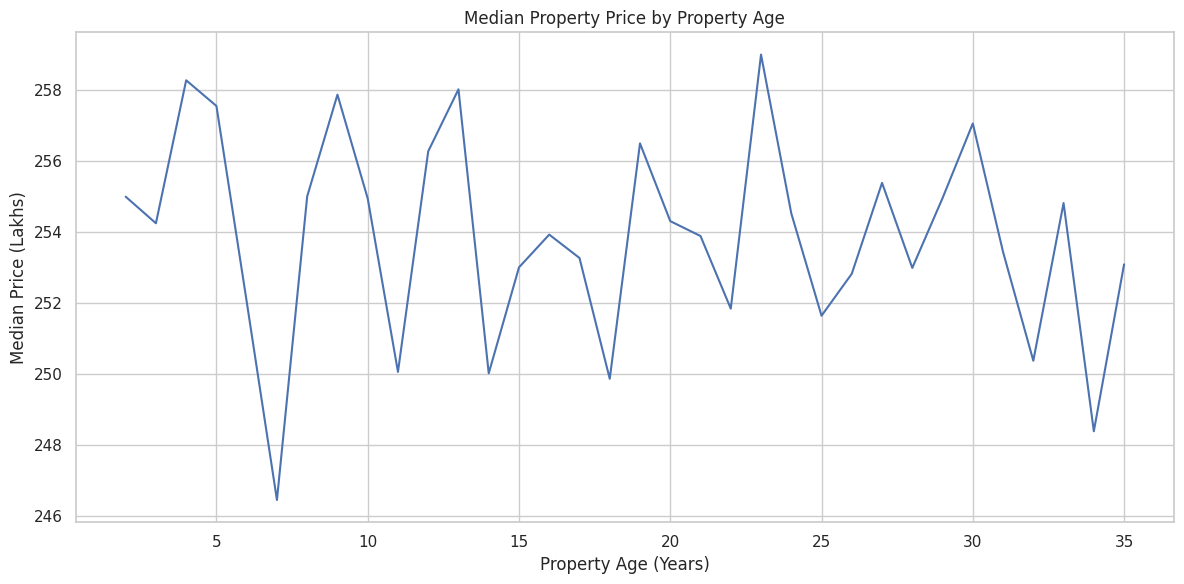

In [26]:
age_price = (
    data.groupby("Age_of_Property", as_index=False)["Price_in_Lakhs"]
    .median()
)

plt.figure(figsize=(12, 6))
sns.lineplot(data=age_price, x="Age_of_Property", y="Price_in_Lakhs")
plt.title("Median Property Price by Property Age")
plt.xlabel("Property Age (Years)")
plt.ylabel("Median Price (Lakhs)")
plt.tight_layout()
plt.show()

### **Chart 11 Interpretation**

**Why this chart?**  
Property age is an ordered numerical variable, so a line chart makes the trend easy to inspect.

**Insight:**  
The chart shows how median prices vary across property ages.

**Business impact:**  
Age is useful when assessing maintenance, resale potential and long-term value.

# **EDA Chart 12 - Parking and Price**

Compare prices for properties with and without parking.

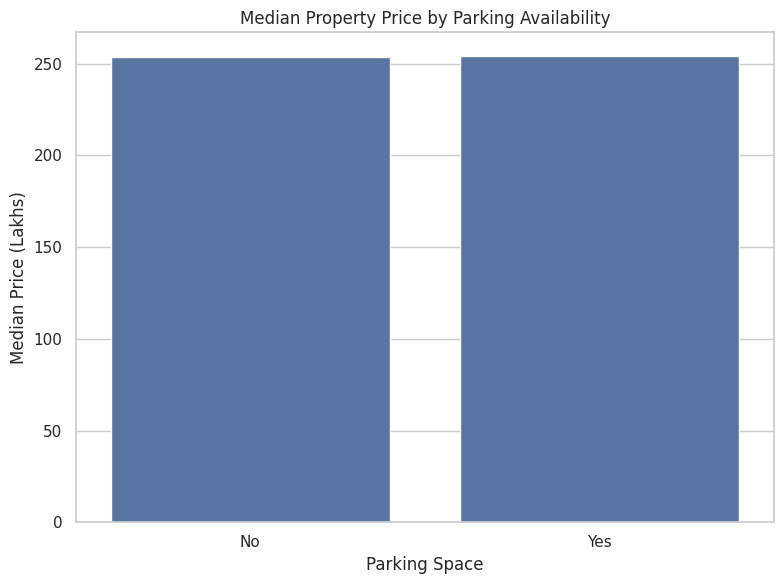

In [27]:
parking_price = (
    data.groupby("Parking_Space", as_index=False)["Price_in_Lakhs"]
    .median()
)

plt.figure(figsize=(8, 6))
sns.barplot(data=parking_price, x="Parking_Space", y="Price_in_Lakhs")
plt.title("Median Property Price by Parking Availability")
plt.xlabel("Parking Space")
plt.ylabel("Median Price (Lakhs)")
plt.tight_layout()
plt.show()

### **Chart 12 Interpretation**

**Why this chart?**  
A bar chart gives a simple comparison between two parking categories.

**Insight:**  
It shows whether parking availability is associated with a price difference.

**Business impact:**  
Parking can be an important property attribute, particularly in urban locations.

# **EDA Chart 13 - Schools and Hospitals vs Price**

Use a scatter plot to investigate whether nearby educational and healthcare facilities are related to price.

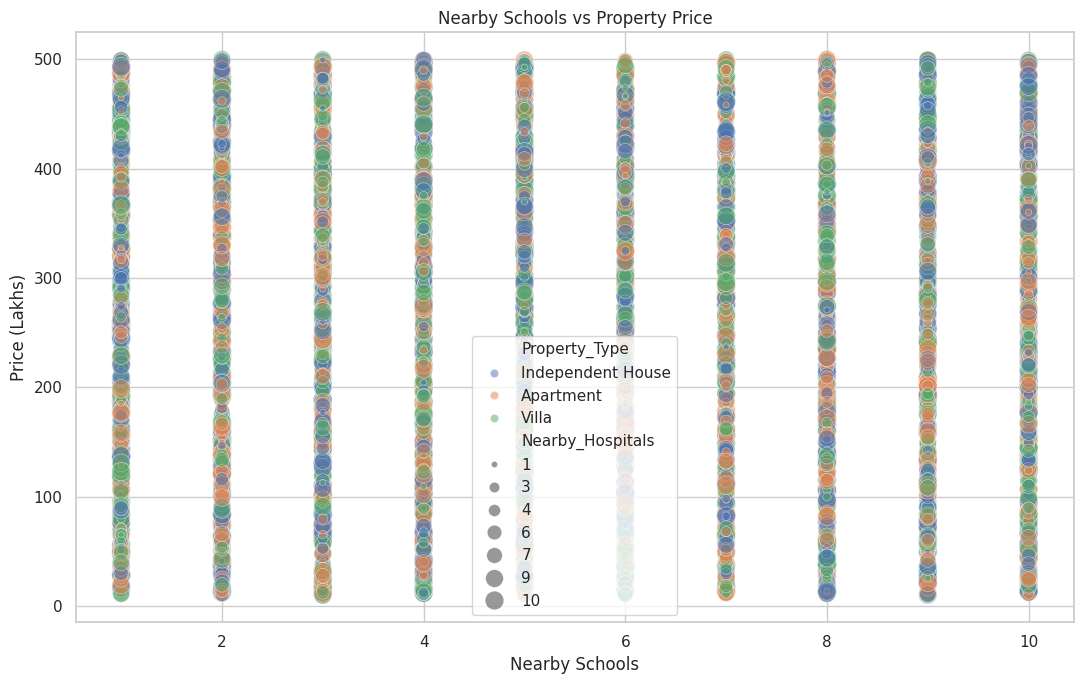

In [28]:
sample_plot = data.sample(min(10000, len(data)), random_state=RANDOM_STATE)

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=sample_plot,
    x="Nearby_Schools",
    y="Price_in_Lakhs",
    size="Nearby_Hospitals",
    hue="Property_Type",
    alpha=0.5,
    sizes=(20, 180)
)
plt.title("Nearby Schools vs Property Price")
plt.xlabel("Nearby Schools")
plt.ylabel("Price (Lakhs)")
plt.tight_layout()
plt.show()

### **Chart 13 Interpretation**

**Why this chart?**  
A scatter plot reveals numerical relationships, while color and point size add useful categorical/multivariate context.

**Insight:**  
The visualization helps identify whether properties with stronger local education/healthcare access tend to have different price levels.

**Business impact:**  
These factors can contribute to location attractiveness and resale demand.

# **EDA Chart 14 - Numerical Correlation Heatmap**

Inspect correlations among important numerical features.

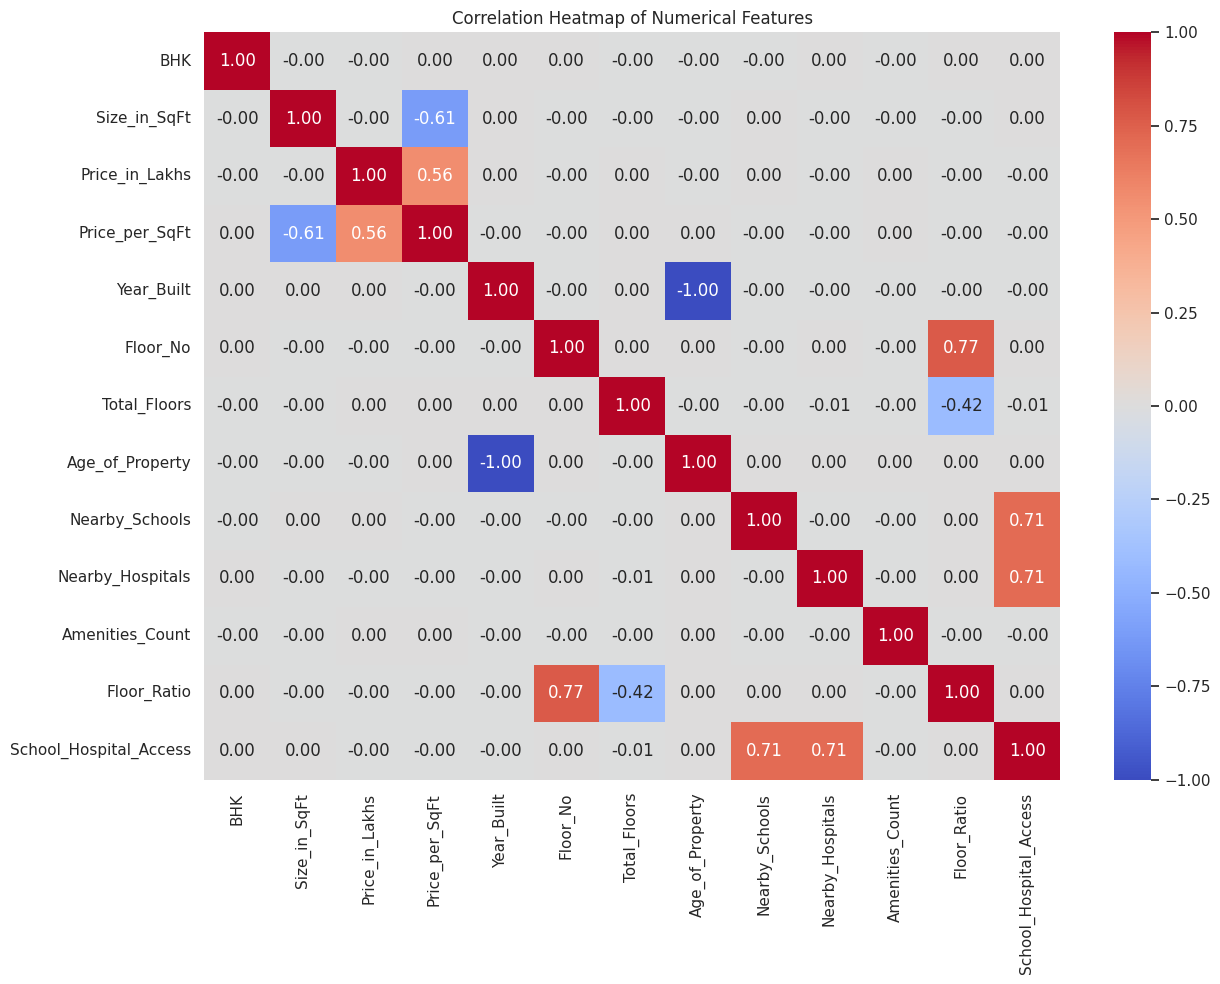

In [29]:
corr_cols = [
    "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt",
    "Year_Built", "Floor_No", "Total_Floors", "Age_of_Property",
    "Nearby_Schools", "Nearby_Hospitals", "Amenities_Count",
    "Floor_Ratio", "School_Hospital_Access"
]

corr_matrix = data[corr_cols].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

### **Chart 14 Interpretation**

**Why this chart?**  
A heatmap summarizes many pairwise correlations in one compact visualization.

**Insight:**  
It highlights strongly related variables and helps detect redundant features.

**Business impact:**  
Understanding relationships improves feature selection and reduces the risk of unnecessarily complex models.

# **EDA Chart 15 - Property Price by Availability Status**

Compare properties that are ready to move with properties under construction.

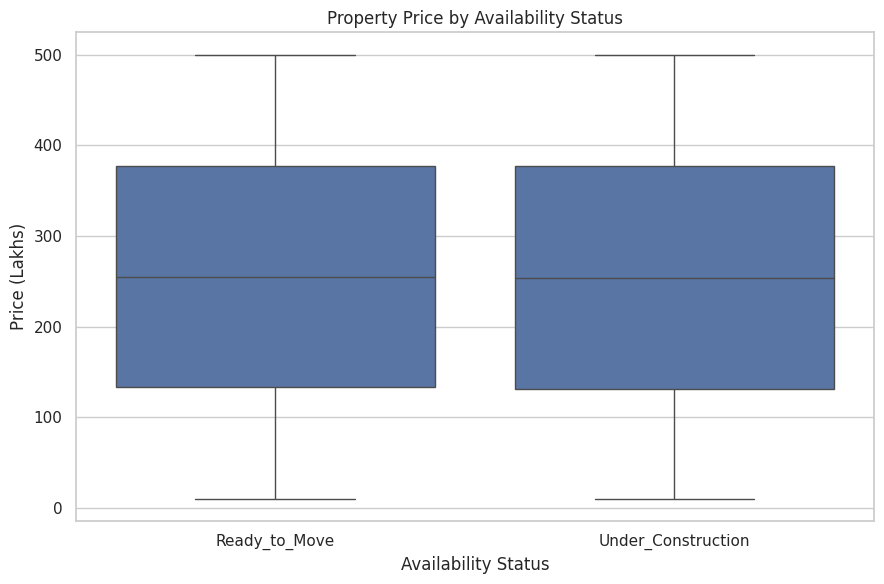

In [30]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=data, x="Availability_Status", y="Price_in_Lakhs")
plt.title("Property Price by Availability Status")
plt.xlabel("Availability Status")
plt.ylabel("Price (Lakhs)")
plt.tight_layout()
plt.show()

### **Chart 15 Interpretation**

**Why this chart?**  
A boxplot compares the full price distributions of the two availability categories.

**Insight:**  
It shows whether availability status is associated with different price ranges.

**Business impact:**  
Investors can compare immediate-use properties with under-construction opportunities.

# **EDA Chart 16 - City and Property Type Interaction**

A grouped bar chart shows how average price changes across property types for the highest-priced cities.

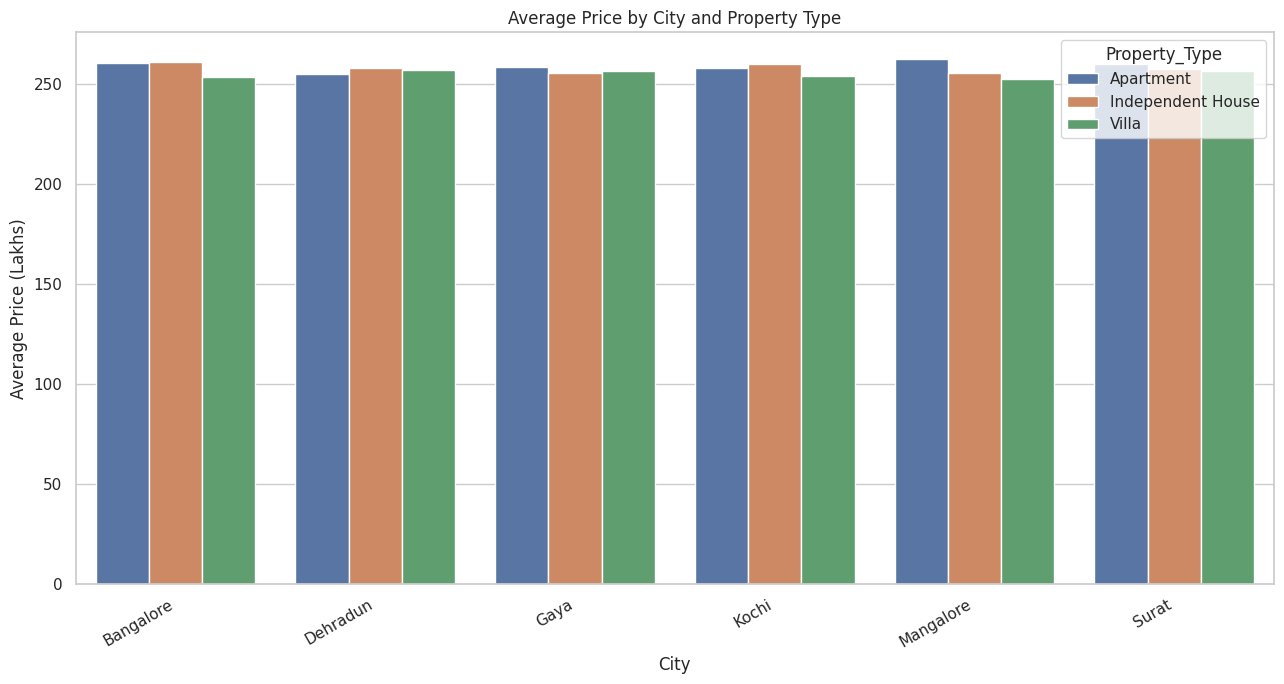

In [31]:
top_city_names = (
    data.groupby("City")["Price_in_Lakhs"]
    .mean()
    .nlargest(6)
    .index
)

city_type = (
    data[data["City"].isin(top_city_names)]
    .groupby(["City", "Property_Type"], as_index=False)["Price_in_Lakhs"]
    .mean()
)

plt.figure(figsize=(13, 7))
sns.barplot(
    data=city_type,
    x="City",
    y="Price_in_Lakhs",
    hue="Property_Type"
)
plt.title("Average Price by City and Property Type")
plt.xlabel("City")
plt.ylabel("Average Price (Lakhs)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### **Chart 16 Interpretation**

**Why this chart?**  
A grouped bar chart is appropriate for comparing two categorical dimensions against one numerical measure.

**Insight:**  
The chart shows that property type and city can interact in determining price.

**Business impact:**  
Investment decisions should consider both location and property category rather than evaluating either variable in isolation.

# **Create the Good Investment Target**

The dataset does not contain a ready-made `Good_Investment` label.

Following the project specification, we create a transparent domain-rule score using:

- price compared with the city median;
- price per square foot compared with the city median;
- BHK;
- ready-to-move status;
- security;
- public transport;
- parking;
- number of amenities.

A property is labelled **Good Investment** when it reaches at least 5 points.

**Modeling caveat:** this is a rule-derived target, not an independently observed investment outcome. Therefore, the classifier is learning to reproduce the defined investment-screening policy.

In [32]:
# City-level reference values prevent large cities from being compared directly
# with unrelated markets.
city_median_price = data.groupby("City")["Price_in_Lakhs"].transform("median")
city_median_ppsft = data.groupby("City")["Price_per_SqFt"].transform("median")

data["Price_vs_City_Median"] = (
    data["Price_in_Lakhs"] <= city_median_price
).astype(int)

data["PPSqFt_vs_City_Median"] = (
    data["Price_per_SqFt"] <= city_median_ppsft
).astype(int)

data["Investment_Score"] = (
    data["Price_vs_City_Median"]
    + data["PPSqFt_vs_City_Median"]
    + (data["BHK"] >= 3).astype(int)
    + data["Is_Ready_To_Move"]
    + data["Has_Security"]
    + (data["Public_Transport_Accessibility"] == "High").astype(int)
    + data["Has_Parking"]
    + (data["Amenities_Count"] >= 3).astype(int)
)

data["Good_Investment"] = (data["Investment_Score"] >= 5).astype(int)

print(data["Good_Investment"].value_counts())
print("\nInvestment score distribution:")
display(data["Investment_Score"].value_counts().sort_index().to_frame("Properties"))

Good_Investment
0    154559
1     95441
Name: count, dtype: int64

Investment score distribution:


,Properties
Investment_Score,
0,1324
1,9311
2,28338
3,52040
4,63546
5,53419
6,30473
7,10062
8,1487


# **Classification Target Distribution**

Check whether the Good Investment target is reasonably balanced.

A severe imbalance would require additional evaluation strategies and possibly class weighting.

,Count,Percentage
Not Good Investment,NaN,NaN
Good Investment,NaN,NaN


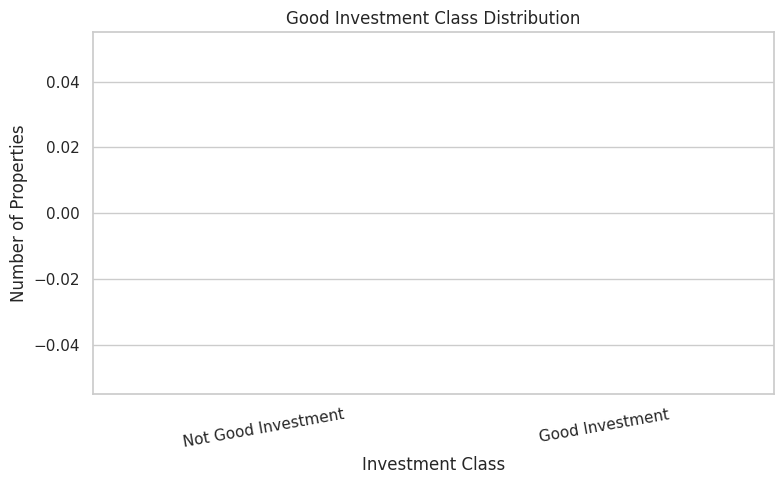

In [33]:
target_counts = data["Good_Investment"].value_counts().sort_index()
target_pct = data["Good_Investment"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_pct.round(2)
}, index=["Not Good Investment", "Good Investment"])

display(target_summary)

plt.figure(figsize=(8, 5))
sns.barplot(x=target_summary.index, y=target_summary["Count"].values)
plt.title("Good Investment Class Distribution")
plt.xlabel("Investment Class")
plt.ylabel("Number of Properties")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

# **Create the Five-Year Future Price Target**

The supplied dataset has no observed future-sale price.

Therefore, we create a **scenario-based target** using a transparent annual appreciation assumption:

- Base annual appreciation: **8%**
- Small property-type adjustment
- Small accessibility/security adjustment
- Age adjustment

The resulting target is:

`Future_Price_5Y = Current_Price × (1 + Annual_Appreciation_Rate)^5`

This follows the project document's suggested fixed-rate / feature-based approach. Because the target is engineered rather than observed, the regression results must be described as a scenario-based ML exercise.

In [34]:
# Base appreciation assumption.
base_rate = 0.08

property_rate_adjustment = {
    "Apartment": 0.000,
    "Independent House": 0.005,
    "Villa": 0.010
}

transport_adjustment = {
    "Low": -0.005,
    "Medium": 0.000,
    "High": 0.005
}

data["Annual_Appreciation_Rate"] = base_rate

data["Annual_Appreciation_Rate"] += data["Property_Type"].map(
    property_rate_adjustment
).fillna(0)

data["Annual_Appreciation_Rate"] += data["Public_Transport_Accessibility"].map(
    transport_adjustment
).fillna(0)

data["Annual_Appreciation_Rate"] += np.where(
    data["Age_of_Property"] <= 10, 0.003,
    np.where(data["Age_of_Property"] >= 25, -0.003, 0)
)

data["Annual_Appreciation_Rate"] += np.where(
    data["Has_Security"] == 1, 0.002, 0
)

# Keep the scenario within a reasonable bounded range.
data["Annual_Appreciation_Rate"] = data["Annual_Appreciation_Rate"].clip(0.04, 0.12)

data["Future_Price_5Y"] = (
    data["Price_in_Lakhs"]
    * (1 + data["Annual_Appreciation_Rate"]) ** 5
)

display(
    data[
        [
            "Price_in_Lakhs",
            "Annual_Appreciation_Rate",
            "Future_Price_5Y"
        ]
    ].head()
)

print(
    "Future price range:",
    f"{data['Future_Price_5Y'].min():.2f}",
    "to",
    f"{data['Future_Price_5Y'].max():.2f}",
    "lakhs"
)

,Price_in_Lakhs,Annual_Appreciation_Rate,Future_Price_5Y
0,489.7600,0.0820,726.3060
1,195.5200,0.0820,289.9529
2,183.7900,0.0720,260.1931
3,300.2900,0.0890,459.9179
4,182.9000,0.0870,277.5629


Future price range: 14.33 to 804.74 lakhs


# **Prepare Classification Features**

The classification target is explicitly derived from price and price-per-square-foot rules.

To avoid giving the classifier the exact rule components as direct inputs, the model feature set excludes:

- `Price_vs_City_Median`
- `PPSqFt_vs_City_Median`
- `Investment_Score`
- `Good_Investment`
- `Future_Price_5Y`
- `Annual_Appreciation_Rate`
- identifier `ID`

The raw `Price_in_Lakhs` and `Price_per_SqFt` remain available because the eventual investment advisor is expected to use the actual property price as an input. The target-definition caveat should therefore be stated when presenting the model.

In [35]:
classification_drop = [
    "ID",
    "Locality",
    "Price_vs_City_Median",
    "PPSqFt_vs_City_Median",
    "Investment_Score",
    "Good_Investment",
    "Future_Price_5Y",
    "Annual_Appreciation_Rate"
]

X_cls = data.drop(columns=classification_drop)
y_cls = data["Good_Investment"]

print("Classification feature shape:", X_cls.shape)
print("Target shape:", y_cls.shape)

Classification feature shape: (250000, 28)
Target shape: (250000,)


# **Prepare Regression Features**

For regression, the target is `Future_Price_5Y`.

The target itself and the engineered appreciation rate used to construct it are excluded from the input features.

In [36]:
regression_drop = [
    "ID",
    "Locality",
    "Good_Investment",
    "Future_Price_5Y",
    "Annual_Appreciation_Rate",
    "Price_vs_City_Median",
    "PPSqFt_vs_City_Median",
    "Investment_Score"
]

X_reg = data.drop(columns=regression_drop)
y_reg = data["Future_Price_5Y"]

print("Regression feature shape:", X_reg.shape)
print("Target shape:", y_reg.shape)

Regression feature shape: (250000, 28)
Target shape: (250000,)


# **Train-Test Split - Classification**

Use a stratified split so the proportion of Good Investment and Not Good Investment properties is preserved in both training and testing sets.

In [37]:
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_cls
)

print("Classification training rows:", f"{len(X_train_cls):,}")
print("Classification testing rows :", f"{len(X_test_cls):,}")

Classification training rows: 200,000
Classification testing rows : 50,000


# **Train-Test Split - Regression**

Use a separate 80/20 split for the future-price regression task.

In [38]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Regression training rows:", f"{len(X_train_reg):,}")
print("Regression testing rows :", f"{len(X_test_reg):,}")

Regression training rows: 200,000
Regression testing rows : 50,000


# **Build Preprocessing Pipelines**

Use `ColumnTransformer` so preprocessing is learned only from training data.

- Numerical variables: median imputation + standard scaling.
- Categorical variables: most-frequent imputation + one-hot encoding.

`handle_unknown="ignore"` makes the pipeline safe when deployment data contains a category not seen during training.

In [39]:
def build_preprocessor(X):
    numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
    categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, numeric_features),
            ("cat", categorical_pipeline, categorical_features)
        ],
        remainder="drop"
    )

    return preprocessor, numeric_features, categorical_features

preprocessor_cls, num_cls, cat_cls = build_preprocessor(X_train_cls)
preprocessor_reg, num_reg, cat_reg = build_preprocessor(X_train_reg)

print("Classification numerical features:", len(num_cls))
print("Classification categorical features:", len(cat_cls))
print("Regression numerical features:", len(num_reg))
print("Regression categorical features:", len(cat_reg))

Classification numerical features: 16
Classification categorical features: 12
Regression numerical features: 16
Regression categorical features: 12


# **MLflow Configuration**

MLflow will track:

- model name;
- hyperparameters;
- validation/test metrics;
- model artifacts;
- the final model file.

The local MLflow tracking directory is saved under `/kaggle/working`, which is available as a Kaggle notebook output artifact.

In [40]:
# Use a SQLite backend because MLflow's legacy filesystem tracking backend is deprecated.
MLFLOW_DB = OUTPUT_DIR / "mlflow.db"
MLFLOW_ARTIFACTS = OUTPUT_DIR / "mlflow_artifacts"
MLFLOW_ARTIFACTS.mkdir(parents=True, exist_ok=True)

mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")

EXPERIMENT_NAME = "Real_Estate_Investment_Advisor"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)


2026/10/29 10:21:38 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/29 10:21:38 INFO mlflow.store.db.utils: Updating database tables
2026/10/29 10:21:40 INFO mlflow.tracking.fluent: Experiment with name 'Real_Estate_Investment_Advisor' does not exist. Creating a new experiment.


MLflow tracking URI: sqlite:////kaggle/working/real_estate_ml/mlflow.db
MLflow experiment: Real_Estate_Investment_Advisor


# **Classification Model Evaluation Function**

Create a reusable function so every classification algorithm is evaluated consistently.

The business-facing metrics are:

- Accuracy: overall correctness.
- Precision: reliability of Good Investment predictions.
- Recall: ability to find genuinely Good Investment properties under the engineered rule.
- F1-score: balance between precision and recall.
- ROC-AUC: ranking ability when probability scores are available.

In [41]:
def evaluate_classifier(model, X_test, y_test, model_name):
    predictions = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, probabilities)
    else:
        probabilities = None
        roc_auc = np.nan

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc
    }

    print(f"\n===== {model_name} =====")
    print(classification_report(y_test, predictions, digits=4))

    cm = confusion_matrix(y_test, predictions)
    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Good", "Good"],
        yticklabels=["Not Good", "Good"]
    )
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    return metrics

# **Classification Model 1 - Logistic Regression**

Logistic Regression provides a strong, interpretable linear baseline.

MLflow records the model parameters and evaluation metrics for comparison with tree-based models.


===== Logistic Regression =====
              precision    recall  f1-score   support

           0     0.9563    0.9192    0.9374     30912
           1     0.8769    0.9319    0.9036     19088

    accuracy                         0.9241     50000
   macro avg     0.9166    0.9256    0.9205     50000
weighted avg     0.9260    0.9241    0.9245     50000



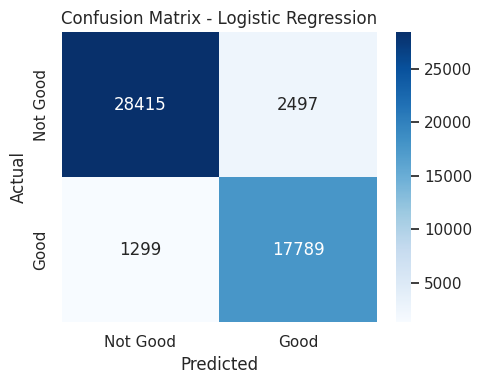

{'Model': 'Logistic Regression',
 'Accuracy': 0.92408,
 'Precision': 0.8769101843636005,
 'Recall': 0.9319467728415759,
 'F1': 0.9035912023162493,
 'ROC_AUC': np.float64(0.9827374881691033)}

In [42]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor_cls),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

with mlflow.start_run(run_name="classification_logistic_regression") as run:
    logistic_pipeline.fit(X_train_cls, y_train_cls)

    logistic_metrics = evaluate_classifier(
        logistic_pipeline,
        X_test_cls,
        y_test_cls,
        "Logistic Regression"
    )

    mlflow.log_params({
        "model": "LogisticRegression",
        "max_iter": 1000,
        "class_weight": "balanced"
    })
    mlflow.log_metrics({
        k: float(v) for k, v in logistic_metrics.items()
        if k != "Model" and pd.notna(v)
    })
    mlflow.sklearn.log_model(
        logistic_pipeline,
        name="logistic_regression_model",
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.compose._column_transformer._RemainderColsList"
        ]
    )

logistic_metrics

# **Classification Model 2 - Random Forest**

Random Forest can model nonlinear relationships and interactions between property characteristics.

The configuration is intentionally moderate so a 250,000-row dataset remains practical on Kaggle.


===== Random Forest Classifier =====
              precision    recall  f1-score   support

           0     0.9823    0.9309    0.9559     30912
           1     0.8968    0.9728    0.9333     19088

    accuracy                         0.9469     50000
   macro avg     0.9395    0.9518    0.9446     50000
weighted avg     0.9496    0.9469    0.9472     50000



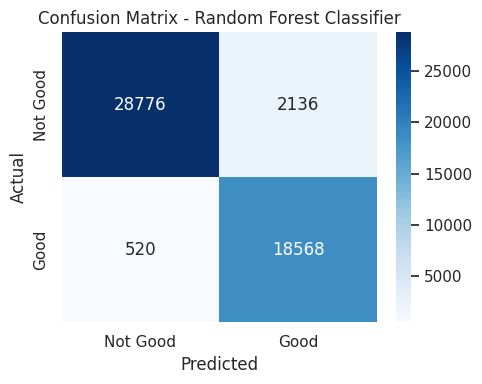

{'Model': 'Random Forest Classifier',
 'Accuracy': 0.94688,
 'Precision': 0.8968315301391035,
 'Recall': 0.9727577535624476,
 'F1': 0.9332529151588259,
 'ROC_AUC': np.float64(0.9951697798086535)}

In [43]:
rf_cls_pipeline = Pipeline([
    ("preprocessor", preprocessor_cls),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

with mlflow.start_run(run_name="classification_random_forest") as run:
    rf_cls_pipeline.fit(X_train_cls, y_train_cls)

    rf_cls_metrics = evaluate_classifier(
        rf_cls_pipeline,
        X_test_cls,
        y_test_cls,
        "Random Forest Classifier"
    )

    mlflow.log_params({
        "model": "RandomForestClassifier",
        "n_estimators": 200,
        "max_depth": 12,
        "min_samples_leaf": 2,
        "class_weight": "balanced"
    })
    mlflow.log_metrics({
        k: float(v) for k, v in rf_cls_metrics.items()
        if k != "Model" and pd.notna(v)
    })
    mlflow.sklearn.log_model(
        rf_cls_pipeline,
        name="random_forest_classifier",
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.compose._column_transformer._RemainderColsList",
            "sklearn.tree._tree.Tree"
        ]
    )

rf_cls_metrics

# **Classification Model 3 - XGBoost**

XGBoost is included because it is explicitly listed in the project architecture.

The histogram tree method and moderate depth are selected for efficient training on a large dataset.


===== XGBoost Classifier =====
              precision    recall  f1-score   support

           0     0.9983    0.9985    0.9984     30912
           1     0.9975    0.9972    0.9974     19088

    accuracy                         0.9980     50000
   macro avg     0.9979    0.9979    0.9979     50000
weighted avg     0.9980    0.9980    0.9980     50000



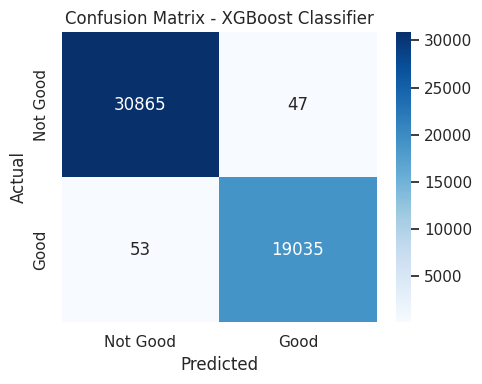

{'Model': 'XGBoost Classifier',
 'Accuracy': 0.998,
 'Precision': 0.9975369458128078,
 'Recall': 0.9972233864207879,
 'F1': 0.9973801414723605,
 'ROC_AUC': np.float64(0.9999854825433124)}

In [44]:
xgb_cls_pipeline = Pipeline([
    ("preprocessor", preprocessor_cls),
    ("model", XGBClassifier(
        n_estimators=250,
        max_depth=8,
        learning_rate=0.08,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

with mlflow.start_run(run_name="classification_xgboost") as run:
    xgb_cls_pipeline.fit(X_train_cls, y_train_cls)

    xgb_cls_metrics = evaluate_classifier(
        xgb_cls_pipeline,
        X_test_cls,
        y_test_cls,
        "XGBoost Classifier"
    )

    mlflow.log_params({
        "model": "XGBClassifier",
        "n_estimators": 250,
        "max_depth": 8,
        "learning_rate": 0.08,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "tree_method": "hist"
    })
    mlflow.log_metrics({
        k: float(v) for k, v in xgb_cls_metrics.items()
        if k != "Model" and pd.notna(v)
    })
    mlflow.sklearn.log_model(
        xgb_cls_pipeline,
        name="xgboost_classifier",
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.compose._column_transformer._RemainderColsList",
            "xgboost.core.Booster",
            "xgboost.sklearn.XGBClassifier"
        ]
    )

xgb_cls_metrics

# **Classification Model Comparison**

Compare all three baseline classifiers using the same test set.

In [45]:
classification_results = pd.DataFrame([
    logistic_metrics,
    rf_cls_metrics,
    xgb_cls_metrics
]).sort_values("F1", ascending=False).reset_index(drop=True)

display(classification_results)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,XGBoost Classifier,0.9980,0.9975,0.9972,0.9974,1.0000
1,Random Forest Classifier,0.9469,0.8968,0.9728,0.9333,0.9952
2,Logistic Regression,0.9241,0.8769,0.9319,0.9036,0.9827


# **Classification Performance Chart**

A model-comparison chart makes the difference between the candidate classifiers easier to communicate.

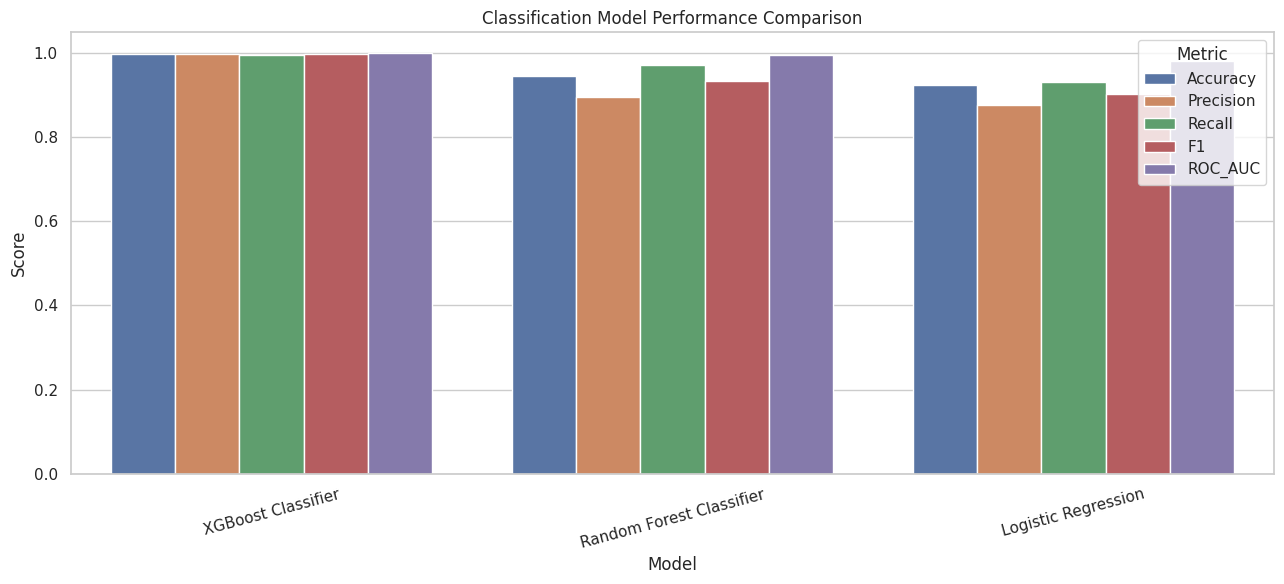

In [46]:
plot_cls = classification_results.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))
sns.barplot(data=plot_cls, x="Model", y="Score", hue="Metric")
plt.title("Classification Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### **Classification Model Interpretation**

The model with the strongest overall **F1-score** is the preferred candidate because the investment-screening task should balance identifying good opportunities with avoiding excessive false positives.

Accuracy alone should not be used to select the model.

# **Classification Cross-Validation**

Use stratified 3-fold cross-validation on the best baseline candidate.

Cross-validation checks whether the model's performance is reasonably stable across different training/validation splits.

In [47]:
best_cls_name = classification_results.iloc[0]["Model"]

classification_models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest Classifier": rf_cls_pipeline,
    "XGBoost Classifier": xgb_cls_pipeline
}

best_cls_pipeline = classification_models[best_cls_name]

cv_cls = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_scores_cls = cross_validate(
    best_cls_pipeline,
    X_train_cls,
    y_train_cls,
    cv=cv_cls,
    scoring=["accuracy", "precision", "recall", "f1"],
    n_jobs=-1
)

cv_cls_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1"],
    "Mean": [
        cv_scores_cls["test_accuracy"].mean(),
        cv_scores_cls["test_precision"].mean(),
        cv_scores_cls["test_recall"].mean(),
        cv_scores_cls["test_f1"].mean()
    ],
    "Std": [
        cv_scores_cls["test_accuracy"].std(),
        cv_scores_cls["test_precision"].std(),
        cv_scores_cls["test_recall"].std(),
        cv_scores_cls["test_f1"].std()
    ]
})

display(cv_cls_summary)

,Metric,Mean,Std
0,Accuracy,0.9974,0.0002
1,Precision,0.9970,0.0002
2,Recall,0.9963,0.0003
3,F1,0.9967,0.0002


# **Classification Hyperparameter Tuning**

Tune the selected classifier with a limited randomized search.

A randomized search is used instead of a large exhaustive grid because the dataset contains 250,000 records and model training is computationally expensive.

Fitting 3 folds for each of 5 candidates, totalling 15 fits

===== Tuned XGBoost Classifier =====
              precision    recall  f1-score   support

           0     0.9981    0.9984    0.9983     30912
           1     0.9974    0.9970    0.9972     19088

    accuracy                         0.9978     50000
   macro avg     0.9978    0.9977    0.9977     50000
weighted avg     0.9978    0.9978    0.9978     50000



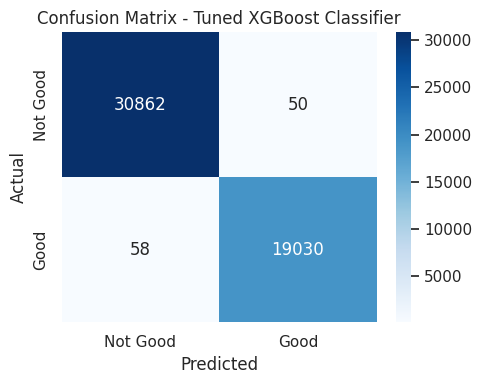

Best classification parameters:
{'model__subsample': 0.75, 'model__n_estimators': 200, 'model__max_depth': 8, 'model__learning_rate': 0.08, 'model__colsample_bytree': 0.75}


In [48]:
# Tune only tree-based candidates if one of them wins the baseline comparison.
# Logistic Regression uses a smaller parameter space and can be tuned separately.
if best_cls_name == "Random Forest Classifier":
    param_dist_cls = {
        "model__n_estimators": [150, 200, 250],
        "model__max_depth": [8, 10, 12, 16],
        "model__min_samples_leaf": [1, 2, 4]
    }
elif best_cls_name == "XGBoost Classifier":
    param_dist_cls = {
        "model__n_estimators": [150, 200, 250, 300],
        "model__max_depth": [5, 7, 8, 10],
        "model__learning_rate": [0.05, 0.08, 0.1],
        "model__subsample": [0.75, 0.85, 1.0],
        "model__colsample_bytree": [0.75, 0.85, 1.0]
    }
else:
    param_dist_cls = {
        "model__C": [0.1, 0.5, 1, 2, 5]
    }

search_cls = RandomizedSearchCV(
    estimator=best_cls_pipeline,
    param_distributions=param_dist_cls,
    n_iter=5,
    scoring="f1",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

search_cls.fit(X_train_cls, y_train_cls)

tuned_cls_pipeline = search_cls.best_estimator_

tuned_cls_metrics = evaluate_classifier(
    tuned_cls_pipeline,
    X_test_cls,
    y_test_cls,
    f"Tuned {best_cls_name}"
)

print("Best classification parameters:")
print(search_cls.best_params_)

# **Log Tuned Classification Experiment to MLflow**

Track the tuned model separately so the baseline and tuned experiments can be compared in MLflow.

In [49]:
with mlflow.start_run(run_name="classification_tuned_best_model"):
    mlflow.log_params(search_cls.best_params_)
    mlflow.log_metrics({
        k: float(v) for k, v in tuned_cls_metrics.items()
        if k != "Model" and pd.notna(v)
    })
    mlflow.sklearn.log_model(
        tuned_cls_pipeline,
        name="tuned_classification_model",
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.compose._column_transformer._RemainderColsList",
            "sklearn.tree._tree.Tree",
            "xgboost.core.Booster",
            "xgboost.sklearn.XGBClassifier"
        ]
    )

classification_final = pd.DataFrame([
    classification_results.iloc[0].to_dict(),
    tuned_cls_metrics
])

display(classification_final)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,XGBoost Classifier,0.9980,0.9975,0.9972,0.9974,1.0000
1,Tuned XGBoost Classifier,0.9978,0.9974,0.9970,0.9972,1.0000


# **Regression Evaluation Function**

Evaluate regression models using:

- MAE: average absolute prediction error.
- RMSE: penalizes larger errors more strongly.
- R²: proportion of target variance explained by the model.

For an investment application, MAE and RMSE are especially useful because they are expressed in the same unit as property price.

In [50]:
def evaluate_regressor(model, X_test, y_test, model_name):
    predictions = model.predict(X_test)

    metrics = {
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    }

    print(f"\n===== {model_name} =====")
    print(f"MAE  : {metrics['MAE']:.4f}")
    print(f"RMSE : {metrics['RMSE']:.4f}")
    print(f"R²   : {metrics['R2']:.4f}")

    return metrics, predictions

# **Regression Model 1 - Linear Regression**

Linear Regression provides a simple baseline for the future-price task.

In [51]:
linear_reg_pipeline = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("model", LinearRegression())
])

with mlflow.start_run(run_name="regression_linear_regression"):
    linear_reg_pipeline.fit(X_train_reg, y_train_reg)

    linear_metrics, linear_predictions = evaluate_regressor(
        linear_reg_pipeline,
        X_test_reg,
        y_test_reg,
        "Linear Regression"
    )

    mlflow.log_param("model", "LinearRegression")
    mlflow.log_metrics({
        k: float(v) for k, v in linear_metrics.items()
        if k != "Model"
    })
    mlflow.sklearn.log_model(
        linear_reg_pipeline,
        name="linear_regression_model",
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.compose._column_transformer._RemainderColsList"
        ]
    )

linear_metrics


===== Linear Regression =====
MAE  : 4.6285
RMSE : 6.3673
R²   : 0.9991


{'Model': 'Linear Regression',
 'MAE': 4.628466448087848,
 'RMSE': np.float64(6.367260397279457),
 'R2': 0.9991115442443939}

# **Regression Model 2 - Random Forest Regressor**

Random Forest can capture nonlinear relationships between property characteristics and the engineered future-price target.

This implementation uses a reduced forest size and row subsampling to keep training practical on the 250,000-row dataset.


In [52]:

# Use a smaller but still meaningful forest for Kaggle-scale training.
# max_samples reduces the number of training rows seen by each tree,
# substantially lowering training time while retaining ensemble averaging.
rf_reg_pipeline = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("model", RandomForestRegressor(
        n_estimators=80,
        max_depth=12,
        min_samples_leaf=3,
        max_samples=0.70,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

rf_reg_start = time.perf_counter()

with mlflow.start_run(run_name="regression_random_forest"):
    rf_reg_pipeline.fit(X_train_reg, y_train_reg)

    rf_reg_metrics, rf_reg_predictions = evaluate_regressor(
        rf_reg_pipeline,
        X_test_reg,
        y_test_reg,
        "Random Forest Regressor"
    )

    mlflow.log_params({
        "model": "RandomForestRegressor",
        "n_estimators": 80,
        "max_depth": 12,
        "min_samples_leaf": 3,
        "max_samples": 0.70,
        "n_jobs": -1,
        "random_state": RANDOM_STATE
    })

    mlflow.log_metrics({
        k: float(v) for k, v in rf_reg_metrics.items()
        if k != "Model" and pd.notna(v)
    })

    mlflow.sklearn.log_model(
        rf_reg_pipeline,
        name="random_forest_regressor",
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.compose._column_transformer._RemainderColsList",
            "sklearn.tree._tree.Tree"
        ]
    )

rf_reg_elapsed = time.perf_counter() - rf_reg_start
print(f"Random Forest training + evaluation + MLflow logging time: {rf_reg_elapsed/60:.2f} minutes")

rf_reg_metrics



===== Random Forest Regressor =====
MAE  : 1.4622
RMSE : 1.7952
R²   : 0.9999
Random Forest training + evaluation + MLflow logging time: 7.25 minutes


{'Model': 'Random Forest Regressor',
 'MAE': 1.462159928102883,
 'RMSE': np.float64(1.7952217322828747),
 'R2': 0.9999293736476635}

# **Regression Model 3 - XGBoost Regressor**

XGBoost is used as a strong nonlinear regression candidate and is configured with histogram-based training for efficiency.

In [53]:
xgb_reg_pipeline = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("model", XGBRegressor(
        n_estimators=250,
        max_depth=8,
        learning_rate=0.08,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="reg:squarederror",
        eval_metric="rmse",
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

with mlflow.start_run(run_name="regression_xgboost"):
    xgb_reg_pipeline.fit(X_train_reg, y_train_reg)

    xgb_reg_metrics, xgb_reg_predictions = evaluate_regressor(
        xgb_reg_pipeline,
        X_test_reg,
        y_test_reg,
        "XGBoost Regressor"
    )

    mlflow.log_params({
        "model": "XGBRegressor",
        "n_estimators": 250,
        "max_depth": 8,
        "learning_rate": 0.08,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "tree_method": "hist"
    })
    mlflow.log_metrics({
        k: float(v) for k, v in xgb_reg_metrics.items()
        if k != "Model"
    })
    mlflow.sklearn.log_model(
        xgb_reg_pipeline,
        name="xgboost_regressor",
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.compose._column_transformer._RemainderColsList",
            "xgboost.core.Booster",
            "xgboost.sklearn.XGBRegressor"
        ]
    )

xgb_reg_metrics


===== XGBoost Regressor =====
MAE  : 0.8316
RMSE : 1.0229
R²   : 1.0000


{'Model': 'XGBoost Regressor',
 'MAE': 0.8315534559887338,
 'RMSE': np.float64(1.0229200681396051),
 'R2': 0.9999770694759343}

# **Regression Model Comparison**

Compare the baseline regression models using MAE, RMSE and R².

In [54]:
regression_results = pd.DataFrame([
    linear_metrics,
    rf_reg_metrics,
    xgb_reg_metrics
]).sort_values("RMSE", ascending=True).reset_index(drop=True)

display(regression_results)

,Model,MAE,RMSE,R2
0,XGBoost Regressor,0.8316,1.0229,1.0000
1,Random Forest Regressor,1.4622,1.7952,0.9999
2,Linear Regression,4.6285,6.3673,0.9991


# **Regression Performance Chart**

Lower MAE/RMSE and higher R² indicate better performance.

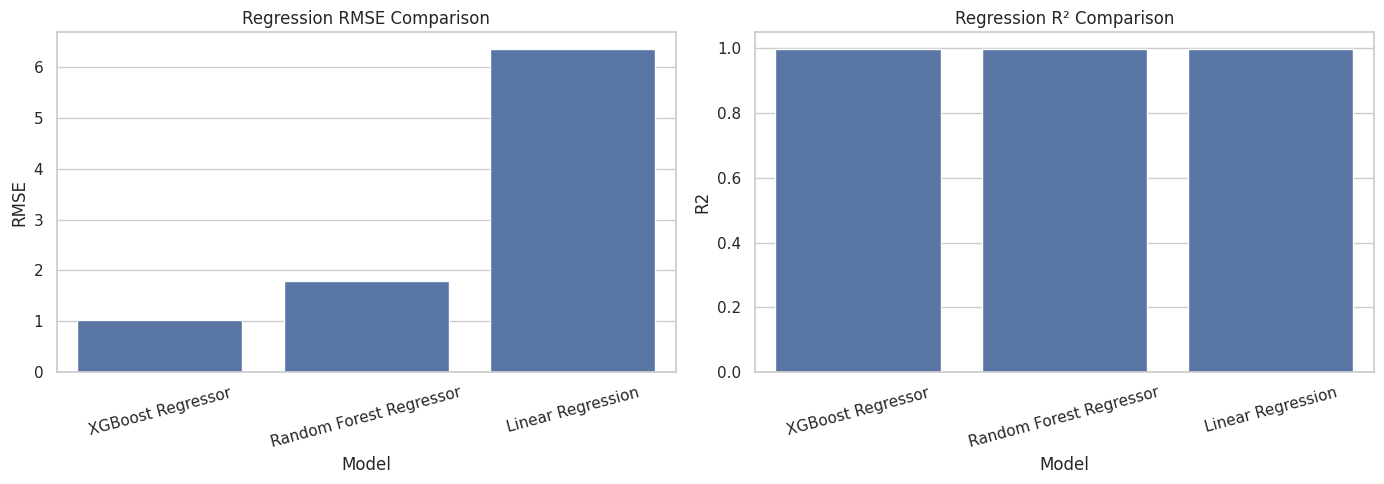

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=regression_results,
    x="Model",
    y="RMSE",
    ax=axes[0]
)
axes[0].set_title("Regression RMSE Comparison")
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(
    data=regression_results,
    x="Model",
    y="R2",
    ax=axes[1]
)
axes[1].set_title("Regression R² Comparison")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

### **Regression Model Interpretation**

The preferred baseline is the model with the **lowest RMSE**, provided its R² and MAE are also competitive.

Because the five-year target is engineered from an appreciation scenario rather than observed future transactions, the model's performance should be interpreted as how well it learns the defined scenario—not as evidence of real-world five-year market accuracy.

# **Regression Cross-Validation**

Perform 3-fold cross-validation on the strongest baseline regression model.

Cross-validation helps determine whether performance is stable across different training/validation splits.

In [56]:

regression_models = {
    "Linear Regression": linear_reg_pipeline,
    "Random Forest Regressor": rf_reg_pipeline,
    "XGBoost Regressor": xgb_reg_pipeline
}

best_reg_name = regression_results.iloc[0]["Model"]
best_reg_pipeline = regression_models[best_reg_name]

cv_reg = KFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_start = time.perf_counter()

cv_scores_reg = cross_validate(
    best_reg_pipeline,
    X_train_reg,
    y_train_reg,
    cv=cv_reg,
    scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"],
    n_jobs=-1,
    return_train_score=False
)

print(f"3-fold regression CV time: {(time.perf_counter()-cv_start)/60:.2f} minutes")

cv_reg_summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Mean": [
        -cv_scores_reg["test_neg_mean_absolute_error"].mean(),
        -cv_scores_reg["test_neg_root_mean_squared_error"].mean(),
        cv_scores_reg["test_r2"].mean()
    ],
    "Std": [
        cv_scores_reg["test_neg_mean_absolute_error"].std(),
        cv_scores_reg["test_neg_root_mean_squared_error"].std(),
        cv_scores_reg["test_r2"].std()
    ]
})

display(cv_reg_summary)


3-fold regression CV time: 0.26 minutes


,Metric,Mean,Std
0,MAE,0.8692,0.0047
1,RMSE,1.0787,0.0073
2,R2,1.0000,0.0000


# **Regression Hyperparameter Tuning**

Tune the selected regression model with a small randomized search.

The search is deliberately constrained to keep execution practical on Kaggle.

In [57]:

if best_reg_name == "Random Forest Regressor":
    param_dist_reg = {
        "model__n_estimators": [60, 80, 100],
        "model__max_depth": [8, 10, 12],
        "model__min_samples_leaf": [2, 3, 4],
        "model__max_samples": [0.60, 0.70, 0.80]
    }
elif best_reg_name == "XGBoost Regressor":
    param_dist_reg = {
        "model__n_estimators": [100, 150, 200],
        "model__max_depth": [5, 7, 8],
        "model__learning_rate": [0.05, 0.08, 0.10],
        "model__subsample": [0.75, 0.85, 1.0],
        "model__colsample_bytree": [0.75, 0.85, 1.0]
    }
else:
    param_dist_reg = {
        "model__fit_intercept": [True, False]
    }

# Keep tuning deliberately small because the dataset contains 250,000 rows.
search_reg = RandomizedSearchCV(
    estimator=best_reg_pipeline,
    param_distributions=param_dist_reg,
    n_iter=4,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

tuning_start = time.perf_counter()

search_reg.fit(X_train_reg, y_train_reg)

print(f"Regression hyperparameter tuning time: {(time.perf_counter()-tuning_start)/60:.2f} minutes")

tuned_reg_pipeline = search_reg.best_estimator_

tuned_reg_metrics, tuned_reg_predictions = evaluate_regressor(
    tuned_reg_pipeline,
    X_test_reg,
    y_test_reg,
    f"Tuned {best_reg_name}"
)

print("Best regression parameters:")
print(search_reg.best_params_)


Fitting 3 folds for each of 4 candidates, totalling 12 fits
Regression hyperparameter tuning time: 0.71 minutes

===== Tuned XGBoost Regressor =====
MAE  : 0.7973
RMSE : 0.9553
R²   : 1.0000
Best regression parameters:
{'model__subsample': 0.85, 'model__n_estimators': 200, 'model__max_depth': 7, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}


# **Log Tuned Regression Experiment to MLflow**

Store the tuned regression experiment and its final test metrics.

In [58]:
with mlflow.start_run(run_name="regression_tuned_best_model"):
    mlflow.log_params(search_reg.best_params_)
    mlflow.log_metrics({
        k: float(v) for k, v in tuned_reg_metrics.items()
        if k != "Model"
    })
    mlflow.sklearn.log_model(
        tuned_reg_pipeline,
        name="tuned_regression_model",
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.compose._column_transformer._RemainderColsList",
            "sklearn.tree._tree.Tree",
            "xgboost.core.Booster",
            "xgboost.sklearn.XGBRegressor"
        ]
    )

regression_final = pd.DataFrame([
    regression_results.iloc[0].to_dict(),
    tuned_reg_metrics
])

display(regression_final)

,Model,MAE,RMSE,R2
0,XGBoost Regressor,0.8316,1.0229,1.0000
1,Tuned XGBoost Regressor,0.7973,0.9553,1.0000


# **Actual vs Predicted Future Price**

Check whether predictions follow the true engineered target closely.

A well-performing model should produce points close to the diagonal reference line.

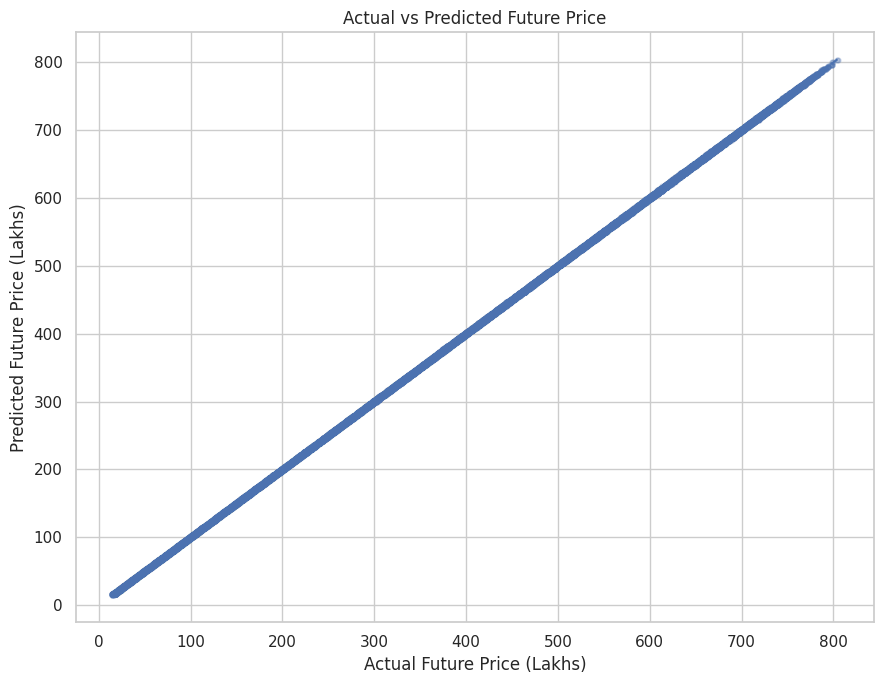

In [59]:
plt.figure(figsize=(9, 7))
plt.scatter(
    y_test_reg,
    tuned_reg_predictions,
    alpha=0.25,
    s=12
)

min_val = min(y_test_reg.min(), tuned_reg_predictions.min())
max_val = max(y_test_reg.max(), tuned_reg_predictions.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.title("Actual vs Predicted Future Price")
plt.xlabel("Actual Future Price (Lakhs)")
plt.ylabel("Predicted Future Price (Lakhs)")
plt.tight_layout()
plt.show()

# **Classification Feature Importance**

Use permutation importance on the final classification pipeline.

Permutation importance measures how much model performance changes when a feature is randomly shuffled, which is easier to interpret than raw tree-specific importance when preprocessing is included in a pipeline.

In [60]:
# Use a manageable sample for permutation importance because the dataset is large.
perm_sample = X_test_cls.sample(
    min(5000, len(X_test_cls)),
    random_state=RANDOM_STATE
)
perm_target = y_test_cls.loc[perm_sample.index]

perm_cls = permutation_importance(
    tuned_cls_pipeline,
    perm_sample,
    perm_target,
    scoring="f1",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

feature_importance_cls = pd.DataFrame({
    "Feature": perm_sample.columns,
    "Importance": perm_cls.importances_mean
}).sort_values("Importance", ascending=False)

display(feature_importance_cls.head(15))

,Feature,Importance
6,Price_per_SqFt,0.1854
5,Price_in_Lakhs,0.1848
24,Is_Ready_To_Move,0.1676
23,Has_Security,0.1629
22,Has_Parking,0.1621
3,BHK,0.1580
21,Amenities_Count,0.1577
14,Public_Transport_Accessibility,0.1492
15,Parking_Space,0.0008
16,Security,0.0005


# **Regression Feature Importance**

Use permutation importance to identify the variables most useful for predicting the engineered five-year price target.

In [61]:
perm_sample_reg = X_test_reg.sample(
    min(5000, len(X_test_reg)),
    random_state=RANDOM_STATE
)
perm_target_reg = y_test_reg.loc[perm_sample_reg.index]

perm_reg = permutation_importance(
    tuned_reg_pipeline,
    perm_sample_reg,
    perm_target_reg,
    scoring="neg_root_mean_squared_error",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

feature_importance_reg = pd.DataFrame({
    "Feature": perm_sample_reg.columns,
    "Importance": perm_reg.importances_mean
}).sort_values("Importance", ascending=False)

display(feature_importance_reg.head(15))

,Feature,Importance
5,Price_in_Lakhs,301.6272
14,Public_Transport_Accessibility,11.0627
2,Property_Type,10.8497
7,Year_Built,5.6668
23,Has_Security,2.1165
6,Price_per_SqFt,0.0220
4,Size_in_SqFt,0.0077
0,State,0.0007
27,Property_Age_Band,0.0006
13,Nearby_Hospitals,0.0003


# **Save Final Models and Metadata**

Save the complete sklearn pipelines rather than only the estimator.

This is important because the pipeline contains the same preprocessing steps required when new property data is passed to the future Streamlit application.

In [62]:
import io

classification_model_path = OUTPUT_DIR / "best_classification_pipeline.joblib"
regression_model_path = OUTPUT_DIR / "best_regression_pipeline.joblib"
classification_h5_path = OUTPUT_DIR / "best_classification_model.h5"
regression_h5_path = OUTPUT_DIR / "best_regression_model.h5"
metadata_path = OUTPUT_DIR / "model_metadata.json"

# The tuned pipelines contain both preprocessing and the final estimator.
# They are the deployable artifacts for the later Streamlit application.
joblib.dump(tuned_cls_pipeline, classification_model_path)
joblib.dump(tuned_reg_pipeline, regression_model_path)

# Also package the complete pipelines inside HDF5 containers because the
# project requests .h5 model files. These are HDF5 model packages, not
# native Keras models. The original sklearn/XGBoost pipeline remains the
# authoritative deployable model and is stored in the corresponding .joblib file.
try:
    import h5py

    def save_pipeline_h5(pipeline, path, model_name):
        buffer = io.BytesIO()
        joblib.dump(pipeline, buffer)
        payload = np.frombuffer(buffer.getvalue(), dtype=np.uint8)
        with h5py.File(path, "w") as h5:
            h5.attrs["format"] = "sklearn_pipeline_hdf5_package"
            h5.attrs["model_name"] = model_name
            h5.attrs["note"] = (
                "This HDF5 file packages a serialized sklearn/XGBoost pipeline; "
                "it is not a native Keras .h5 model. Use the .joblib artifact for deployment."
            )
            h5.create_dataset("joblib_pipeline", data=payload, compression="gzip")

    save_pipeline_h5(
        tuned_cls_pipeline,
        classification_h5_path,
        tuned_cls_metrics["Model"]
    )
    save_pipeline_h5(
        tuned_reg_pipeline,
        regression_h5_path,
        tuned_reg_metrics["Model"]
    )
    h5_status = "HDF5 packages created successfully."
except ImportError:
    h5_status = "h5py is not available; the .joblib deployment artifacts were still created."

metadata = {
    "classification_model": tuned_cls_metrics["Model"],
    "classification_best_params": search_cls.best_params_,
    "classification_joblib": str(classification_model_path),
    "classification_h5_package": str(classification_h5_path),
    "regression_model": tuned_reg_metrics["Model"],
    "regression_best_params": search_reg.best_params_,
    "regression_joblib": str(regression_model_path),
    "regression_h5_package": str(regression_h5_path),
    "random_state": RANDOM_STATE,
    "dataset_rows": int(len(data)),
    "dataset_columns": int(data.shape[1]),
    "future_price_target_note": (
        "Future_Price_5Y is an engineered scenario target because the "
        "source dataset contains no observed five-year future prices."
    ),
    "h5_note": (
        "The .h5 files are HDF5 packages containing the sklearn/XGBoost pipelines, "
        "not native Keras models. The .joblib files are the recommended deployment artifacts."
    )
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, default=str)

print("Saved files:")
print(classification_model_path)
print(regression_model_path)
print(classification_h5_path)
print(regression_h5_path)
print(metadata_path)
print(h5_status)


Saved files:
/kaggle/working/real_estate_ml/best_classification_pipeline.joblib
/kaggle/working/real_estate_ml/best_regression_pipeline.joblib
/kaggle/working/real_estate_ml/best_classification_model.h5
/kaggle/working/real_estate_ml/best_regression_model.h5
/kaggle/working/real_estate_ml/model_metadata.json
HDF5 packages created successfully.


# **Final ML Results Summary**

Summarize the selected models and their evaluation metrics in one place.

This table can be used later in the project report and presentation.

In [63]:
final_classification = pd.DataFrame([tuned_cls_metrics])
final_regression = pd.DataFrame([tuned_reg_metrics])

print("===== FINAL CLASSIFICATION MODEL =====")
display(final_classification)

print("\n===== FINAL REGRESSION MODEL =====")
display(final_regression)

===== FINAL CLASSIFICATION MODEL =====


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Tuned XGBoost Classifier,0.9978,0.9974,0.9970,0.9972,1.0000



===== FINAL REGRESSION MODEL =====


,Model,MAE,RMSE,R2
0,Tuned XGBoost Regressor,0.7973,0.9553,1.0000


# **MLflow Artifact Summary**

The notebook stores MLflow experiment data under the Kaggle working directory.

The logged runs contain model parameters, evaluation metrics and serialized model artifacts. These can be used for experiment comparison and later model-management work.

In [64]:
print("MLflow tracking database:")
print(MLFLOW_DB)

print("MLflow artifact directory:")
print(MLFLOW_ARTIFACTS)

print("\nMLflow experiments:")

experiments = mlflow.search_experiments()

experiments_df = pd.DataFrame([
    {
        "experiment_id": exp.experiment_id,
        "name": exp.name,
        "artifact_location": exp.artifact_location,
        "lifecycle_stage": exp.lifecycle_stage
    }
    for exp in experiments
])

display(experiments_df[[
    "experiment_id",
    "name",
    "artifact_location",
    "lifecycle_stage"
]])

runs = mlflow.search_runs(
    experiment_names=["Real_Estate_Investment_Advisor"],
    order_by=["start_time DESC"]
)

run_columns = [
    "run_id",
    "status",
    "start_time",
    "tags.mlflow.runName",
    "metrics.Accuracy",
    "metrics.F1",
    "metrics.RMSE",
    "metrics.R2"
]

available_columns = [col for col in run_columns if col in runs.columns]

display(runs[available_columns].head(20))

MLflow tracking database:
/kaggle/working/real_estate_ml/mlflow.db
MLflow artifact directory:
/kaggle/working/real_estate_ml/mlflow_artifacts

MLflow experiments:


,experiment_id,name,artifact_location,lifecycle_stage
0,1,Real_Estate_Investment_Advisor,/kaggle/working/mlruns/1,active
1,0,Default,/kaggle/working/mlruns/0,active


,run_id,status,start_time,tags.mlflow.runName,metrics.Accuracy,metrics.F1,metrics.RMSE,metrics.R2
0,fe9386982f774e29a8f7d6c6e3b8b790,FINISHED,2026-10-29 10:32:48.133000+00:00,regression_tuned_best_model,NaN,NaN,0.9553,1.0000
1,050c3d536eae48e29fdef0ca37d51577,FINISHED,2026-10-29 10:31:37.944000+00:00,regression_xgboost,NaN,NaN,1.0229,1.0000
2,55ddc2b09487456294f8e06e404293b2,FINISHED,2026-10-29 10:24:22.816000+00:00,regression_random_forest,NaN,NaN,1.7952,0.9999
3,3f5cd706446c46949e353d9ba78ea3f1,FINISHED,2026-10-29 10:24:15.932000+00:00,regression_linear_regression,NaN,NaN,6.3673,0.9991
4,8da3b8aff118423189704ffacc9e564f,FINISHED,2026-10-29 10:24:11.317000+00:00,classification_tuned_best_model,0.9978,0.9972,NaN,NaN
5,9a0d59266d994cfc9191da5619d93161,FINISHED,2026-10-29 10:22:37.376000+00:00,classification_xgboost,0.9980,0.9974,NaN,NaN
6,1739adceb772457fb7a02dbfeacc5fcf,FINISHED,2026-10-29 10:21:59.912000+00:00,classification_random_forest,0.9469,0.9333,NaN,NaN
7,b5a2e5a5c9ca40a5b9c6267bbc1ffcd9,FINISHED,2026-10-29 10:21:40.711000+00:00,classification_logistic_regression,0.9241,0.9036,NaN,NaN


# **ML Conclusion**

The ML phase is complete when:

- the dataset has been validated and cleaned;
- EDA has identified relevant patterns;
- classification and regression targets have been created transparently;
- Logistic Regression, Random Forest and XGBoost have been compared;
- cross-validation and hyperparameter tuning have been performed;
- the best classification and regression pipelines have been evaluated;
- MLflow has recorded the experiments;
- the final complete preprocessing + model pipelines have been saved.

**Next phase:** Streamlit deployment. The deployment notebook/code should load the saved pipelines and provide user inputs for investment classification and five-year price estimation.